# Stage 1 : Organizing Data from dataset:

In [1]:
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    print(dirname)

/kaggle/input
/kaggle/input/private-dataset
/kaggle/input/private-dataset/SmokeRemovalDataset
/kaggle/input/private-dataset/SmokeRemovalDataset/valB
/kaggle/input/private-dataset/SmokeRemovalDataset/testB
/kaggle/input/private-dataset/SmokeRemovalDataset/valA
/kaggle/input/private-dataset/SmokeRemovalDataset/testA
/kaggle/input/private-dataset/SmokeRemovalDataset/trainB
/kaggle/input/private-dataset/SmokeRemovalDataset/trainA


In [2]:
from PIL import ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

In [3]:
import os
import shutil
from tqdm import tqdm

In [4]:
ROOT = "/kaggle/input/private-dataset/SmokeRemovalDataset"

OUTPUT = "/content/drive/MyDrive/Project 1/SmokeRemovalDataset"

In [5]:
train_cases = [
    "TLH_2",
    "TLH_6",
    "TLH_7",
    "TLH_8",
    "TLH_9",
    "TLH_10"
]

val_cases = [
    "TLH_11",
    "TLH_12"
]

test_cases = [
    "TLH_16",
    "TLH_17"
]

In [6]:
folders = [
    "trainA",
    "trainB",
    "valA",
    "valB",
    "testA",
    "testB"
]

for folder in folders:
    os.makedirs(os.path.join(OUTPUT, folder), exist_ok=True)

print("Folder structure created successfully!")

Folder structure created successfully!


In [7]:
def copy_images(case_list, output_folder, image_type):

    """
    image_type:
        hazy  -> Domain A
        clear -> Domain B
    """

    total = 0

    for case in case_list:

        src = os.path.join(ROOT, case, image_type)

        if not os.path.exists(src):
            print(f"Skipping {case} ({image_type})")
            continue

        images = sorted(os.listdir(src))

        for img in tqdm(images, desc=f"{case} ({image_type})"):

            src_path = os.path.join(src, img)

            # Prevent filename collisions
            new_name = f"{case}_{img}"

            dst_path = os.path.join(
                OUTPUT,
                output_folder,
                new_name
            )

            shutil.copy2(src_path, dst_path)

            total += 1

    print(f"\n{output_folder}: {total} images copied.")

In [8]:
# ----------------------------
# Training
# ----------------------------

copy_images(train_cases, "trainA", "hazy")
copy_images(train_cases, "trainB", "clear")

# ----------------------------
# Validation
# ----------------------------

copy_images(val_cases, "valA", "hazy")
copy_images(val_cases, "valB", "clear")

# ----------------------------
# Testing
# ----------------------------

copy_images(test_cases, "testA", "hazy")
copy_images(test_cases, "testB", "clear")

print("\nDataset organization completed!")

Skipping TLH_2 (hazy)
Skipping TLH_6 (hazy)
Skipping TLH_7 (hazy)
Skipping TLH_8 (hazy)
Skipping TLH_9 (hazy)
Skipping TLH_10 (hazy)

trainA: 0 images copied.
Skipping TLH_2 (clear)
Skipping TLH_6 (clear)
Skipping TLH_7 (clear)
Skipping TLH_8 (clear)
Skipping TLH_9 (clear)
Skipping TLH_10 (clear)

trainB: 0 images copied.
Skipping TLH_11 (hazy)
Skipping TLH_12 (hazy)

valA: 0 images copied.
Skipping TLH_11 (clear)
Skipping TLH_12 (clear)

valB: 0 images copied.
Skipping TLH_16 (hazy)
Skipping TLH_17 (hazy)

testA: 0 images copied.
Skipping TLH_16 (clear)
Skipping TLH_17 (clear)

testB: 0 images copied.

Dataset organization completed!


In [9]:
for folder in folders:

    n = len(os.listdir(os.path.join(OUTPUT, folder)))

    print(f"{folder:8s}: {n} images")

trainA  : 0 images
trainB  : 0 images
valA    : 0 images
valB    : 0 images
testA   : 0 images
testB   : 0 images


In [10]:
import random
import matplotlib.pyplot as plt
from PIL import Image

hazy_folder = os.path.join(OUTPUT, "trainA")
clear_folder = os.path.join(OUTPUT, "trainB")

hazy_img = random.choice(os.listdir(hazy_folder))
clear_img = random.choice(os.listdir(clear_folder))

hazy = Image.open(os.path.join(hazy_folder, hazy_img))
clear = Image.open(os.path.join(clear_folder, clear_img))

plt.figure(figsize=(12,6))

plt.subplot(1,2,1)
plt.imshow(hazy)
plt.title("Random Smoky Image")


plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(clear)
plt.title("Random Clear Image")
plt.axis("off")

plt.show()

IndexError: Cannot choose from an empty sequence

# 



Stage 2: Data Loading & Preprocessing

In [11]:
import os
import random

from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader


import torchvision.transforms as transforms

import matplotlib.pyplot as plt

In [12]:
DATASET_PATH = "/kaggle/input/private-dataset/SmokeRemovalDataset"

TRAIN_A = os.path.join(DATASET_PATH, "trainA")
TRAIN_B = os.path.join(DATASET_PATH, "trainB")

VAL_A = os.path.join(DATASET_PATH, "valA")
VAL_B = os.path.join(DATASET_PATH, "valB")

TEST_A = os.path.join(DATASET_PATH, "testA")
TEST_B = os.path.join(DATASET_PATH, "testB")

In [13]:
IMAGE_SIZE = 128

transform = transforms.Compose([

    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

In [14]:
class UnpairedSmokeDataset(Dataset):

    def __init__(self,
                 domainA_path,
                 domainB_path,
                 transform=None):

        self.domainA_path = domainA_path
        self.domainB_path = domainB_path

        self.domainA = sorted(os.listdir(domainA_path))
        self.domainB = sorted(os.listdir(domainB_path))

        self.transform = transform

    def __len__(self):

        return max(len(self.domainA), len(self.domainB))

    def __getitem__(self, index):

        imageA = self.domainA[index % len(self.domainA)]

        imageB = random.choice(self.domainB)

        pathA = os.path.join(self.domainA_path, imageA)
        pathB = os.path.join(self.domainB_path, imageB)

        imageA = Image.open(pathA).convert("RGB")
        imageB = Image.open(pathB).convert("RGB")

        if self.transform:

            imageA = self.transform(imageA)
            imageB = self.transform(imageB)

        return {

            "A": imageA,
            "B": imageB
        }

In [15]:
train_dataset = UnpairedSmokeDataset(

    TRAIN_A,

    TRAIN_B,

    transform=transform

)

In [16]:
val_dataset = UnpairedSmokeDataset(

    VAL_A,

    VAL_B,

    transform=transform

)

In [17]:
test_dataset = UnpairedSmokeDataset(

    TEST_A,

    TEST_B,

    transform=transform

)

In [18]:
BATCH_SIZE = 1

train_loader = DataLoader(

    train_dataset,

    batch_size=BATCH_SIZE,

    shuffle=True,

    num_workers=2,

    pin_memory=True
)

val_loader = DataLoader(

    val_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=2,

    pin_memory=True
)

test_loader = DataLoader(

    test_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=2,

    pin_memory=True
)

In [19]:
batch = next(iter(train_loader))

print(batch["A"].shape)
print(batch["B"].shape)

torch.Size([1, 3, 128, 128])
torch.Size([1, 3, 128, 128])


In [20]:
def denormalize(img):

    img = img * 0.5 + 0.5
    return img.clamp(0,1)

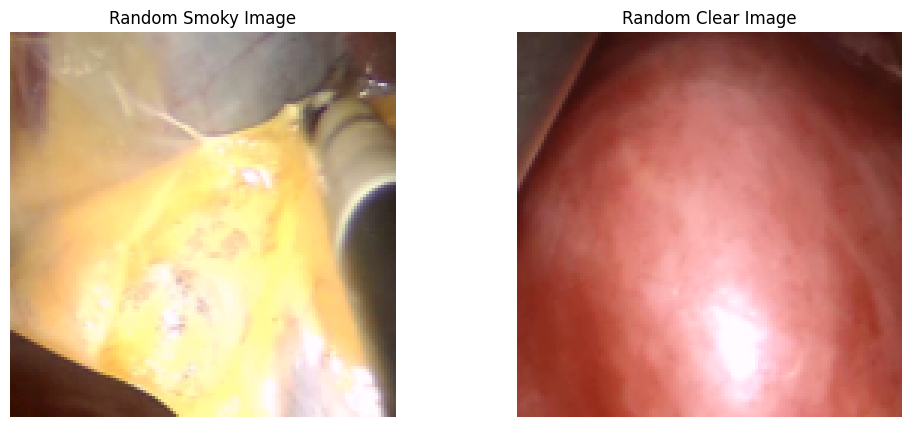

In [21]:
batch = next(iter(train_loader))

smoke = denormalize(batch["A"][0])
clear = denormalize(batch["B"][0])

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.imshow(smoke.permute(1,2,0))
plt.title("Random Smoky Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(clear.permute(1,2,0))
plt.title("Random Clear Image")
plt.axis("off")

plt.show()

# Stage 3: Adaptive Smoke Prior Estimation (ASPE)

In [22]:
import torch
import torch.nn as nn

In [23]:
class ResidualBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(channels, channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(channels, channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(channels)
        )
        self.relu = nn.ReLU(inplace=True)
    def forward(self, x):
        return self.relu(x + self.block(x))

In [24]:
class AdaptiveSmokePriorEstimator(nn.Module):
    def __init__(self):
        super().__init__()
        self.initial = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True)
        )
        self.res1 = ResidualBlock(32)
        self.res2 = ResidualBlock(32)
        self.dilated = nn.Sequential(
            nn.Conv2d(
                32,
                32,
                kernel_size=3,
                padding=2,
                dilation=2
            ),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True)
        )
        self.output = nn.Sequential(
            nn.Conv2d(32, 1, kernel_size=1),
            nn.Sigmoid()
        )
    def forward(self, x):
        x = self.initial(x)
        x = self.res1(x)
        x = self.res2(x)
        x = self.dilated(x)
        smoke_map = self.output(x)
        return smoke_map

In [25]:
model = AdaptiveSmokePriorEstimator()
dummy = torch.randn(2, 3, 256, 256)
smoke_map = model(dummy)
print("Input Shape :", dummy.shape)
print("Smoke Map Shape :", smoke_map.shape)

Input Shape : torch.Size([2, 3, 256, 256])
Smoke Map Shape : torch.Size([2, 1, 256, 256])


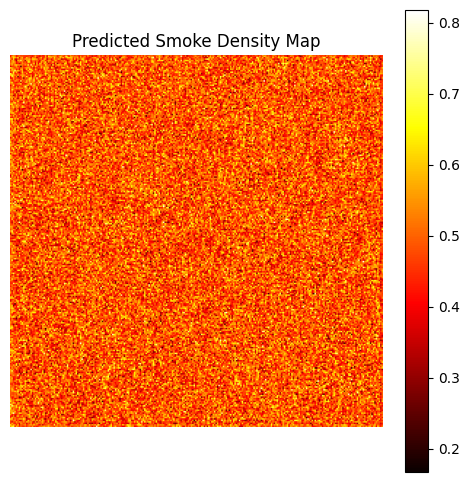

In [26]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6,6))
plt.imshow(smoke_map[0,0].detach().numpy(), cmap="hot")
plt.title("Predicted Smoke Density Map")
plt.colorbar()
plt.axis("off")
plt.show()

# Stage 4 — Adaptive Multiscale Feature Encoder (AMFE)

In [27]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [28]:
class MultiScaleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv3 = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )
        self.conv5 = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=5,
                padding=2
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )
        self.dilated = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=2,
                dilation=2
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        f3 = self.conv3(x)
        f5 = self.conv5(x)
        fd = self.dilated(x)
        return f3, f5, fd

In [29]:
class ScaleWeightPredictor(nn.Module):
    def __init__(self):
        super().__init__()
        self.predictor = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(1,16,1),
            nn.ReLU(),
            nn.Conv2d(16,3,1),
            nn.Softmax(dim=1)
        )
    def forward(self, smoke_map):
        weights = self.predictor(smoke_map)
        return weights

In [30]:
class AdaptiveFeatureFusion(nn.Module):
    def forward(self, f3, f5, fd, weights):
        w1 = weights[:,0:1]
        w2 = weights[:,1:2]
        w3 = weights[:,2:3]
        fused = (
            w1*f3 +
            w2*f5 +
            w3*fd
        )
        return fused

In [ ]:
class AdaptiveMultiscaleEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.multiscale = MultiScaleConv(
            in_channels=3,
            out_channels=64
        )
        self.weight_predictor = ScaleWeightPredictor()
        self.fusion = AdaptiveFeatureFusion()
    def forward(self, x, smoke_map):
        f3,f5,fd = self.multiscale(x)
        weights = self.weight_predictor(smoke_map)
        fused = self.fusion(
            f3,
            f5,
            fd,
            weights
        )
        return fused, weights

In [ ]:
encoder = AdaptiveMultiscaleEncoder()
dummy = torch.randn(2,3,256,256)
smoke = torch.rand(2,1,256,256)
features, weights = encoder(dummy, smoke)
print(features.shape)
print(weights.shape)

In [ ]:
weights = weights.squeeze(-1).squeeze(-1).detach().cpu()
for i in range(weights.shape[0]):
    print(f"Image {i+1}")
    print(f"3×3 Weight     : {weights[i,0]:.3f}")
    print(f"5×5 Weight     : {weights[i,1]:.3f}")
    print(f"Dilated Weight : {weights[i,2]:.3f}")
    print()

# Stage 5 – Frequency-Aware Feature Enhancement Module (FAFEM)

In [ ]:
import torch
import torch.nn as nn

In [ ]:
class FFTFeatureExtractor(nn.Module):
    def __init__(self):
        super().__init__()
    def forward(self, x):
        # FFT
        fft = torch.fft.fft2(x)
        amplitude = torch.abs(fft)
        phase = torch.angle(fft)
        return amplitude, phase

In [ ]:
class HighFrequencyEnhancer(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.enhance = nn.Sequential(
            nn.Conv2d(channels, channels, 1),
            nn.ReLU(inplace=True),
            nn.Conv2d(channels, channels, 1),
            nn.Sigmoid()
        )
    def forward(self, amplitude):
        weight = self.enhance(amplitude)
        enhanced = amplitude * (1 + weight)
        return enhanced

In [ ]:
class InverseFFT(nn.Module):
    def __init__(self):
        super().__init__()
    def forward(self, amplitude, phase):
        real = amplitude * torch.cos(phase)
        imag = amplitude * torch.sin(phase)
        complex_fft = torch.complex(real, imag)
        feature = torch.fft.ifft2(complex_fft).real
        return feature

In [ ]:
class FrequencyAwareFeatureEnhancement(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.fft = FFTFeatureExtractor()
        self.enhancer = HighFrequencyEnhancer(channels)
        self.ifft = InverseFFT()
    def forward(self, x):
        amplitude, phase = self.fft(x)
        enhanced_amplitude = self.enhancer(amplitude)
        output = self.ifft(enhanced_amplitude, phase)
        return output

In [ ]:
freq_module = FrequencyAwareFeatureEnhancement(64)
dummy = torch.randn(2,64,256,256)
out = freq_module(dummy)
print(dummy.shape)
print(out.shape)

In [ ]:
feature = out[0].mean(0).detach().cpu()
plt.figure(figsize=(6,6))
plt.imshow(feature, cmap="viridis")
plt.title("Frequency Enhanced Feature Map")
plt.colorbar()
plt.axis("off")
plt.show()

# Stage 6 — Cross-Domain Feature Fusion (CDFF)

In [ ]:
import torch
import torch.nn as nn

In [ ]:
class ChannelAttention(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Sequential(
            nn.Conv2d(channels, channels // reduction, 1),
            nn.ReLU(inplace=True),
            nn.Conv2d(channels // reduction, channels, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        weight = self.avg_pool(x)
        weight = self.fc(weight)
        return x * weight

In [ ]:
class CrossDomainFusion(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.spatial_attention = ChannelAttention(channels)
        self.frequency_attention = ChannelAttention(channels)
        self.fusion = nn.Sequential(
            nn.Conv2d(channels * 2, channels, kernel_size=1),
            nn.BatchNorm2d(channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, spatial, frequency):
        spatial = self.spatial_attention(spatial)
        frequency = self.frequency_attention(frequency)
        fused = torch.cat([spatial, frequency], dim=1)
        fused = self.fusion(fused)
        return fused

In [ ]:
fusion = CrossDomainFusion(64)

spatial = torch.randn(2, 64, 256, 256)
frequency = torch.randn(2, 64, 256, 256)

output = fusion(spatial, frequency)

print("Spatial Feature Shape :", spatial.shape)
print("Frequency Feature Shape :", frequency.shape)
print("Fused Feature Shape :", output.shape)

In [ ]:
import matplotlib.pyplot as plt

feature = output[0].mean(dim=0).detach().cpu().numpy()

plt.figure(figsize=(6,6))
plt.imshow(feature, cmap="viridis")
plt.title("Cross-Domain Fused Feature Map")
plt.colorbar()
plt.axis("off")
plt.show()

# Stage 7 — Lightweight Global Context Transformer (LGCT)

In [ ]:
import torch
import torch.nn as nn

def window_partition(x, window_size):
    B, C, H, W = x.shape
    x = x.view(B, C, H // window_size, window_size, W // window_size, window_size)
    x = x.permute(0, 2, 4, 3, 5, 1)
    windows = x.reshape(-1, window_size * window_size, C)
    return windows

In [ ]:
def window_reverse(windows, window_size, H, W, B):
    C = windows.shape[-1]
    x = windows.view(B, H // window_size, W // window_size,
                     window_size, window_size, C)
    x = x.permute(0, 5, 1, 3, 2, 4)
    x = x.reshape(B, C, H, W)
    return x

In [ ]:
class WindowAttention(nn.Module):
    def __init__(self, dim, num_heads=4):
        super().__init__()
        self.attn = nn.MultiheadAttention(
            embed_dim=dim,
            num_heads=num_heads,
            batch_first=True
        )

    def forward(self, x):
        out, _ = self.attn(x, x, x)
        return out

In [ ]:
class FeedForward(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(dim, dim * 4),
            nn.GELU(),
            nn.Linear(dim * 4, dim)
        )

    def forward(self, x):
        return self.net(x)

In [ ]:
class WindowTransformerBlock(nn.Module):
    def __init__(self, dim=64, num_heads=4, window_size=8):
        super().__init__()
        self.window_size = window_size
        self.norm1 = nn.LayerNorm(dim)
        self.attn = WindowAttention(dim, num_heads)
        self.norm2 = nn.LayerNorm(dim)
        self.ffn = FeedForward(dim)

    def forward(self, x):
        B, C, H, W = x.shape
        windows = window_partition(x, self.window_size)
        shortcut = windows
        windows = self.norm1(windows)
        windows = shortcut + self.attn(windows)
        windows = windows + self.ffn(self.norm2(windows))
        x = window_reverse(
            windows,
            self.window_size,
            H,
            W,
            B
        )
        return x

In [ ]:
class LightweightGlobalContextTransformer(nn.Module):
    def __init__(self,
                 channels=64,
                 num_heads=4,
                 window_size=8):

        super().__init__()
        self.block1 = WindowTransformerBlock(
            channels,
            num_heads,
            window_size
        )
        self.block2 = WindowTransformerBlock(
            channels,
            num_heads,
            window_size
        )
    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        return x

In [ ]:
model = LightweightGlobalContextTransformer()
dummy = torch.randn(2,64,256,256)
output = model(dummy)
print(dummy.shape)
print(output.shape)

# Stage 8 — Edge-Guided Reconstruction Decoder (EGRD)

In [ ]:
import torch
import torch.nn as nn

class EdgeAttention(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.edge = nn.Sequential(
            nn.Conv2d(channels, channels, 3, padding=1),
            nn.BatchNorm2d(channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(channels, 1, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        edge_map = self.edge(x)
        return x * edge_map, edge_map

In [ ]:
class ResidualRefinement(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(channels, channels, 3, padding=1),
            nn.BatchNorm2d(channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(channels, channels, 3, padding=1),
            nn.BatchNorm2d(channels)
        )
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        return self.relu(x + self.block(x))

In [ ]:
class EdgeGuidedDecoder(nn.Module):
    def __init__(self, channels=64):
        super().__init__()
        self.conv1 = nn.Sequential(
            nn.Conv2d(channels, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True)
        )
        self.edge = EdgeAttention(64)
        self.refine1 = ResidualRefinement(64)
        self.refine2 = ResidualRefinement(64)
        self.output = nn.Sequential(
            nn.Conv2d(64, 3, 1),
            nn.Tanh()
        )
    def forward(self, x):
        x = self.conv1(x)
        x, edge_map = self.edge(x)
        x = self.refine1(x)
        x = self.refine2(x)
        output = self.output(x)
        return output, edge_map

In [ ]:
decoder = EdgeGuidedDecoder()
dummy = torch.randn(2,64,256,256)
output, edge = decoder(dummy)
print(output.shape)
print(edge.shape)

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6,6))
plt.imshow(edge[0,0].detach().cpu(), cmap="gray")
plt.title("Predicted Edge Attention")
plt.axis("off")
plt.show()

# Stage 9 – Complete Generator Integration

In [ ]:
class SmokeRemovalGenerator(nn.Module):
    def __init__(self):
        super().__init__()

        self.aspe = AdaptiveSmokePriorEstimator()

        self.encoder = AdaptiveMultiscaleEncoder()

        self.frequency = FrequencyAwareFeatureEnhancement(64)

        self.fusion = CrossDomainFusion(64)

        self.transformer = LightweightGlobalContextTransformer(
            channels=64,
            num_heads=4,
            window_size=8
        )

        self.decoder = EdgeGuidedDecoder(64)

    def forward(self, x):

        smoke_map = self.aspe(x)

        spatial_features, scale_weights = self.encoder(x, smoke_map)

        frequency_features = self.frequency(spatial_features)

        fused_features = self.fusion(
            spatial_features,
            frequency_features
        )

        transformer_features = self.transformer(fused_features)

        output, edge_map = self.decoder(transformer_features)

        return {
            "output": output,
            "smoke_map": smoke_map,
            "edge_map": edge_map,
            "scale_weights": scale_weights
        }

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

generator = SmokeRemovalGenerator().to(device)

print(generator)

In [ ]:

dummy = torch.randn(2,3,256,256).to(device)

result = generator(dummy)

print("Output Image :", result["output"].shape)
print("Smoke Map :", result["smoke_map"].shape)
print("Edge Map :", result["edge_map"].shape)
print("Scale Weights :", result["scale_weights"].shape)
# print("Spatial Features :", result["spatial_features"].shape)
# print("Frequency Features :", result["frequency_features"].shape)
# print("Fused Features :", result["fused_features"].shape)

In [ ]:
import matplotlib.pyplot as plt

sample = result

fig, ax = plt.subplots(1,3, figsize=(15,5))

output = sample["output"][0].detach().cpu()
output = output * 0.5 + 0.5

ax[0].imshow(output.permute(1,2,0))
ax[0].set_title("Generated Image")
ax[0].axis("off")

ax[1].imshow(sample["smoke_map"][0,0].detach().cpu(), cmap="hot")
ax[1].set_title("Smoke Prior")
ax[1].axis("off")

ax[2].imshow(sample["edge_map"][0,0].detach().cpu(), cmap="gray")
ax[2].set_title("Edge Attention")
ax[2].axis("off")

plt.show()

# Stage 10 – Dual PatchGAN Discriminators

In [ ]:
import torch
import torch.nn as nn

class DiscriminatorBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=2):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 4, stride, 1),
            nn.InstanceNorm2d(out_channels),
            nn.LeakyReLU(0.2, inplace=True)
        )

    def forward(self, x):
        return self.block(x)

In [ ]:
class PatchGANDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()

        self.initial = nn.Sequential(
            nn.Conv2d(3, 64, 4, 2, 1),
            nn.LeakyReLU(0.2, inplace=True)
        )

        self.block1 = DiscriminatorBlock(64, 128)
        self.block2 = DiscriminatorBlock(128, 256)
        self.block3 = DiscriminatorBlock(256, 512, stride=1)

        self.output = nn.Conv2d(
            512,
            1,
            kernel_size=4,
            stride=1,
            padding=1
        )

    def forward(self, x):
        x = self.initial(x)
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.output(x)
        return x

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

D_smoke = PatchGANDiscriminator().to(device)

D_clear = PatchGANDiscriminator().to(device)

In [ ]:
G_smoke_to_clear = SmokeRemovalGenerator().to(device)

G_clear_to_smoke = SmokeRemovalGenerator().to(device)

In [ ]:
dummy = torch.randn(2,3,256,256).to(device)

out = D_clear(dummy)

print(out.shape)

In [ ]:
smoke = torch.randn(2,3,256,256).to(device)

clear = torch.randn(2,3,256,256).to(device)

fake_clear = G_smoke_to_clear(smoke)["output"]

fake_smoke = G_clear_to_smoke(clear)["output"]

score_clear = D_clear(fake_clear)

score_smoke = D_smoke(fake_smoke)

print(fake_clear.shape)
print(fake_smoke.shape)

print(score_clear.shape)
print(score_smoke.shape)

# Stage 11 – Hybrid Multi-Objective Loss Function (HMOL)

In [ ]:
import torch
import torch.nn as nn

adversarial_loss = nn.MSELoss()

In [ ]:
cycle_loss = nn.L1Loss()

In [ ]:
identity_loss = nn.L1Loss()

In [ ]:
class FrequencyLoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.l1 = nn.L1Loss()

    def forward(self, pred, target):

        # Convert to float32 before FFT
        pred = pred.float()
        target = target.float()

        pred_fft = torch.abs(torch.fft.fft2(pred))
        target_fft = torch.abs(torch.fft.fft2(target))

        return self.l1(pred_fft, target_fft)

In [ ]:
frequency_loss = FrequencyLoss()

In [ ]:
class EdgeLoss(nn.Module):
    def __init__(self):
        super().__init__()

        self.l1 = nn.L1Loss()

        sobel_x = torch.tensor([
            [-1,0,1],
            [-2,0,2],
            [-1,0,1]
        ], dtype=torch.float32)

        sobel_y = torch.tensor([
            [-1,-2,-1],
            [0,0,0],
            [1,2,1]
        ], dtype=torch.float32)

        self.register_buffer(
            "sobel_x",
            sobel_x.view(1,1,3,3)
        )

        self.register_buffer(
            "sobel_y",
            sobel_y.view(1,1,3,3)
        )

    def gradient(self,x):

        gray = x.mean(dim=1,keepdim=True)

        sobel_x = self.sobel_x.to(gray.device)
        sobel_y = self.sobel_y.to(gray.device)

        gx = nn.functional.conv2d(
            gray,
            sobel_x,
            padding=1
        )

        gy = nn.functional.conv2d(
            gray,
            sobel_y,
            padding=1
        )

        return torch.sqrt(gx**2+gy**2+1e-6)

    def forward(self,pred,target):

        return self.l1(
            self.gradient(pred),
            self.gradient(target)
        )

In [ ]:
edge_loss = EdgeLoss()

In [ ]:
class SmokePriorLoss(nn.Module):
    def __init__(self):
        super().__init__()
    def forward(self, smoke_map):
        dx = torch.abs(
            smoke_map[:,:,1:,:]-smoke_map[:,:,:-1,:]
        )
        dy = torch.abs(
            smoke_map[:,:,:,1:]-smoke_map[:,:,:,:-1]
        )
        return dx.mean()+dy.mean()

In [ ]:
smoke_loss = SmokePriorLoss()

In [ ]:
lambda_cycle = 10.0
lambda_identity = 5.0
lambda_frequency = 2.0
lambda_edge = 2.0
lambda_smoke = 0.1

In [ ]:
def generator_loss(
    fake_score,
    fake_img,
    real_img,
    reconstructed_img,
    identity_img,
    smoke_map
):

    gan = adversarial_loss(
        fake_score,
        torch.ones_like(fake_score)
    )

    cycle = cycle_loss(
        reconstructed_img,
        real_img
    )

    identity = identity_loss(
        identity_img,
        real_img
    )

    freq = frequency_loss(
        fake_img,
        real_img
    )

    edge = edge_loss(
        fake_img,
        real_img
    )

    smoke = smoke_loss(
        smoke_map
    )

    total = (
        gan
        + lambda_cycle*cycle
        + lambda_identity*identity
        + lambda_frequency*freq
        + lambda_edge*edge
        + lambda_smoke*smoke
    )

    return total

# Stage 12 — Training Pipeline

In [ ]:
import torch.optim as optim

lr = 2e-4
beta1 = 0.5
beta2 = 0.999

optimizer_G = optim.Adam(
    list(G_smoke_to_clear.parameters()) +
    list(G_clear_to_smoke.parameters()),
    lr=lr,
    betas=(beta1, beta2)
)

optimizer_D_smoke = optim.Adam(
    D_smoke.parameters(),
    lr=lr,
    betas=(beta1, beta2)
)

optimizer_D_clear = optim.Adam(
    D_clear.parameters(),
    lr=lr,
    betas=(beta1, beta2)
)

In [ ]:
scheduler_G = optim.lr_scheduler.StepLR(
    optimizer_G,
    step_size=50,
    gamma=0.5
)

scheduler_D_smoke = optim.lr_scheduler.StepLR(
    optimizer_D_smoke,
    step_size=50,
    gamma=0.5
)

scheduler_D_clear = optim.lr_scheduler.StepLR(
    optimizer_D_clear,
    step_size=50,
    gamma=0.5
)

In [ ]:
def get_labels(prediction):
    real = torch.ones_like(prediction)
    fake = torch.zeros_like(prediction)
    return real, fake

In [ ]:
from torch.amp import GradScaler, autocast
scaler = GradScaler("cuda")

def train_generator(smoke, clear):

    optimizer_G.zero_grad()
    with autocast(device_type="cuda"):
        fake_clear = G_smoke_to_clear(smoke)
        fake_smoke = G_clear_to_smoke(clear)

        reconstructed_smoke = G_clear_to_smoke(fake_clear["output"])
        reconstructed_clear = G_smoke_to_clear(fake_smoke["output"])

        identity_clear = G_smoke_to_clear(clear)
        identity_smoke = G_clear_to_smoke(smoke)

        score_clear = D_clear(fake_clear["output"])
        score_smoke = D_smoke(fake_smoke["output"])

        loss_clear = generator_loss(
            score_clear,
            fake_clear["output"],
            clear,
            reconstructed_clear["output"],
            identity_clear["output"],
            fake_clear["smoke_map"]
        )

        loss_smoke = generator_loss(
            score_smoke,
            fake_smoke["output"],
            smoke,
            reconstructed_smoke["output"],
            identity_smoke["output"],
            fake_smoke["smoke_map"]
        )

        loss = loss_clear + loss_smoke

    scaler.scale(loss).backward()
    scaler.step(optimizer_G)
    scaler.update()

    return loss.item()

In [ ]:
!pip install -q scikit-learn

In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [ ]:
def train_discriminator(discriminator, optimizer, real, fake):
    optimizer.zero_grad()
    pred_real = discriminator(real)
    pred_fake = discriminator(fake.detach())
    real_label = torch.ones_like(pred_real)
    fake_label = torch.zeros_like(pred_fake)
    loss_real = adversarial_loss(pred_real, real_label)
    loss_fake = adversarial_loss(pred_fake, fake_label)
    loss = 0.5 * (loss_real + loss_fake)
    loss.backward()
    optimizer.step()
    real_true = torch.ones_like(pred_real).view(-1).cpu().numpy()
    fake_true = torch.zeros_like(pred_fake).view(-1).cpu().numpy()
    real_pred = (pred_real.detach().view(-1) >= 0.5).cpu().numpy().astype(int)
    fake_pred = (pred_fake.detach().view(-1) >= 0.5).cpu().numpy().astype(int)
    y_true = np.concatenate([real_true, fake_true]).astype(int)
    y_pred = np.concatenate([real_pred, fake_pred])
    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0)
    }
    return loss.item(), metrics

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

edge_loss = EdgeLoss().to(device)
frequency_loss = FrequencyLoss().to(device)
smoke_loss = SmokePriorLoss().to(device)

In [ ]:
import gc
import torch

gc.collect()
torch.cuda.empty_cache()

In [ ]:
history = {
    "G_loss": [],
    "D_loss": [],
    "D_accuracy": [],
    "D_precision": [],
    "D_recall": [],
    "D_f1": [],
    "lr": [],
    "epoch_time": []
}

from tqdm.auto import tqdm
import time
import torch

num_epochs = 20
start_training = time.time()

for epoch in range(num_epochs):
    epoch_start = time.time()
    G_loss_epoch = 0.0
    D_loss_epoch = 0.0
    accuracy_epoch = 0.0
    precision_epoch = 0.0
    recall_epoch = 0.0
    f1_epoch = 0.0

    progress_bar = tqdm(
        enumerate(train_loader),
        total=len(train_loader),
        desc=f"Epoch {epoch+1}/{num_epochs}",
        leave=False
    )

    for batch_idx, batch in progress_bar:
        smoke = batch["A"].to(device)
        clear = batch["B"].to(device)

        G_loss = train_generator(smoke, clear)

        fake_clear = G_smoke_to_clear(smoke)["output"]
        fake_smoke = G_clear_to_smoke(clear)["output"]

        D_clear_loss, D_clear_metrics = train_discriminator(
            D_clear,
            optimizer_D_clear,
            clear,
            fake_clear
        )

        D_smoke_loss, D_smoke_metrics = train_discriminator(
            D_smoke,
            optimizer_D_smoke,
            smoke,
            fake_smoke
        )

        D_loss = D_clear_loss + D_smoke_loss

        avg_accuracy = 0.5 * (
            D_clear_metrics["accuracy"] +
            D_smoke_metrics["accuracy"]
        )

        avg_precision = 0.5 * (
            D_clear_metrics["precision"] +
            D_smoke_metrics["precision"]
        )

        avg_recall = 0.5 * (
            D_clear_metrics["recall"] +
            D_smoke_metrics["recall"]
        )

        avg_f1 = 0.5 * (
            D_clear_metrics["f1"] +
            D_smoke_metrics["f1"]
        )

        G_loss_epoch += G_loss
        D_loss_epoch += D_loss
        accuracy_epoch += avg_accuracy
        precision_epoch += avg_precision
        recall_epoch += avg_recall
        f1_epoch += avg_f1

        progress_bar.set_postfix({
            "G": f"{G_loss:.3f}",
            "D": f"{D_loss:.3f}",
            "Acc": f"{avg_accuracy:.3f}",
            "Prec": f"{avg_precision:.3f}",
            "F1": f"{avg_f1:.3f}"
        })

    scheduler_G.step()
    scheduler_D_clear.step()
    scheduler_D_smoke.step()

    n = len(train_loader)

    G_avg = G_loss_epoch / n
    D_avg = D_loss_epoch / n
    acc_avg = accuracy_epoch / n
    prec_avg = precision_epoch / n
    recall_avg = recall_epoch / n
    f1_avg = f1_epoch / n

    epoch_time = time.time() - epoch_start

    history["G_loss"].append(G_avg)
    history["D_loss"].append(D_avg)
    history["D_accuracy"].append(acc_avg)
    history["D_precision"].append(prec_avg)
    history["D_recall"].append(recall_avg)
    history["D_f1"].append(f1_avg)
    history["lr"].append(optimizer_G.param_groups[0]["lr"])
    history["epoch_time"].append(epoch_time)

    print("\n" + "=" * 90)
    print(f"Epoch {epoch+1}/{num_epochs} Completed")
    print("=" * 90)
    print(f"Generator Loss       : {G_avg:.4f}")
    print(f"Discriminator Loss   : {D_avg:.4f}")
    print(f"Discriminator Accuracy: {acc_avg:.4f}")
    print(f"Discriminator Precision: {prec_avg:.4f}")
    print(f"Discriminator Recall : {recall_avg:.4f}")
    print(f"Discriminator F1     : {f1_avg:.4f}")
    print(f"Learning Rate        : {history['lr'][-1]:.7f}")
    print(f"Epoch Time           : {epoch_time:.2f} sec")
    print("=" * 90)

In [ ]:
import json
import numpy as np

# Convert any tensors/numpy values to normal Python floats
history_save = {}

for key, values in history.items():
    history_save[key] = [
        float(v.item()) if hasattr(v, "item") else float(v)
        for v in values
    ]

with open("training_history.json", "w") as f:
    json.dump(history_save, f, indent=4)

print("Training history saved successfully!")

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

epochs = range(1, len(history["G_loss"]) + 1)

# ============================================================
# 1. Generator and Discriminator Loss
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    epochs,
    history["G_loss"],
    marker="o",
    label="Generator Loss"
)

plt.plot(
    epochs,
    history["D_loss"],
    marker="o",
    label="Discriminator Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Generator vs Discriminator Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 2. Discriminator Accuracy
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    epochs,
    history["D_accuracy"],
    marker="o",
    label="Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Discriminator Accuracy")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 3. Precision, Recall and F1
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    epochs,
    history["D_precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    epochs,
    history["D_recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    epochs,
    history["D_f1"],
    marker="o",
    label="F1 Score"
)

plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("Discriminator Precision, Recall and F1")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 4. Learning Rate
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    epochs,
    history["lr"],
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Learning Rate")
plt.title("Learning Rate Schedule")
plt.yscale("log")
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 5. Epoch Time
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    epochs,
    history["epoch_time"],
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Time (seconds)")
plt.title("Training Time per Epoch")
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

metrics_df = pd.DataFrame({
    "Epoch": list(epochs),
    "Generator Loss": history["G_loss"],
    "Discriminator Loss": history["D_loss"],
    "Accuracy": history["D_accuracy"],
    "Precision": history["D_precision"],
    "Recall": history["D_recall"],
    "F1 Score": history["D_f1"],
    "Learning Rate": history["lr"],
    "Epoch Time (sec)": history["epoch_time"]
})

display(metrics_df)

In [ ]:
metrics_df.to_csv(
    "training_metrics.csv",
    index=False
)

print("Saved: training_metrics.csv")

In [ ]:
print("=" * 70)
print("FINAL TRAINING RESULTS")
print("=" * 70)

print(f"Final Generator Loss       : {history['G_loss'][-1]:.4f}")
print(f"Final Discriminator Loss   : {history['D_loss'][-1]:.4f}")
print(f"Final Discriminator Accuracy: {history['D_accuracy'][-1]:.4f}")
print(f"Final Discriminator Precision: {history['D_precision'][-1]:.4f}")
print(f"Final Discriminator Recall : {history['D_recall'][-1]:.4f}")
print(f"Final Discriminator F1     : {history['D_f1'][-1]:.4f}")
print(f"Final Learning Rate        : {history['lr'][-1]:.7f}")

total_time = sum(history["epoch_time"])

print(f"Total Training Time        : {total_time:.2f} sec")
print(f"Total Training Time        : {total_time/60:.2f} min")

print("=" * 70)

In [ ]:
best_f1_idx = np.argmax(history["D_f1"])

print("Best F1 Epoch:", best_f1_idx + 1)
print("Best F1:", history["D_f1"][best_f1_idx])

In [ ]:
best_acc_idx = np.argmax(history["D_accuracy"])

print("Best Accuracy Epoch:", best_acc_idx + 1)
print("Best Accuracy:", history["D_accuracy"][best_acc_idx])

In [ ]:
best_g_idx = np.argmin(history["G_loss"])

print("Lowest Generator Loss Epoch:", best_g_idx + 1)
print("Lowest Generator Loss:", history["G_loss"][best_g_idx])

In [ ]:
from skimage.metrics import (
    peak_signal_noise_ratio,
    structural_similarity
)

import torch
import numpy as np

G_smoke_to_clear.eval()

total_mse = 0.0
total_mae = 0.0
total_psnr = 0.0
total_ssim = 0.0

num_images = 0

with torch.no_grad():

    for batch in tqdm(test_loader, desc="Evaluating"):

        smoke = batch["A"].to(device)
        real_clear = batch["B"].to(device)

        fake_clear = G_smoke_to_clear(smoke)["output"]

        fake_clear = torch.clamp(fake_clear, 0, 1)
        real_clear = torch.clamp(real_clear, 0, 1)

        batch_size = smoke.size(0)

        for i in range(batch_size):

            generated = fake_clear[i].detach().cpu().numpy()
            target = real_clear[i].detach().cpu().numpy()

            # CHW → HWC
            generated = np.transpose(generated, (1, 2, 0))
            target = np.transpose(target, (1, 2, 0))

            mse = np.mean((generated - target) ** 2)
            mae = np.mean(np.abs(generated - target))

            psnr = peak_signal_noise_ratio(
                target,
                generated,
                data_range=1.0
            )

            ssim = structural_similarity(
                target,
                generated,
                channel_axis=2,
                data_range=1.0
            )

            total_mse += mse
            total_mae += mae
            total_psnr += psnr
            total_ssim += ssim

            num_images += 1


mse_avg = total_mse / num_images
mae_avg = total_mae / num_images
psnr_avg = total_psnr / num_images
ssim_avg = total_ssim / num_images

print("=" * 60)
print("IMAGE TRANSLATION METRICS")
print("=" * 60)

print(f"MSE  : {mse_avg:.6f}")
print(f"MAE  : {mae_avg:.6f}")
print(f"PSNR : {psnr_avg:.4f} dB")
print(f"SSIM : {ssim_avg:.4f}")

print("=" * 60)

In [ ]:
torch.save(
    G_smoke_to_clear.state_dict(),
    "G_smoke_to_clear_final.pth"
)

torch.save(
    G_clear_to_smoke.state_dict(),
    "G_clear_to_smoke_final.pth"
)

torch.save(
    D_clear.state_dict(),
    "D_clear_final.pth"
)

torch.save(
    D_smoke.state_dict(),
    "D_smoke_final.pth"
)

print("All models saved successfully!")

In [ ]:
torch.save({
    "epoch": num_epochs,
    "G_smoke_to_clear": G_smoke_to_clear.state_dict(),
    "G_clear_to_smoke": G_clear_to_smoke.state_dict(),
    "D_clear": D_clear.state_dict(),
    "D_smoke": D_smoke.state_dict(),
    "optimizer_G": optimizer_G.state_dict(),
    "optimizer_D_clear": optimizer_D_clear.state_dict(),
    "optimizer_D_smoke": optimizer_D_smoke.state_dict(),
    "history": history
}, "final_checkpoint.pth")

print("Complete checkpoint saved!")

In [ ]:
import os
import torch

SAVE_DIR = "/kaggle/working/models"
os.makedirs(SAVE_DIR, exist_ok=True)

torch.save(
    G_smoke_to_clear.state_dict(),
    os.path.join(SAVE_DIR, "SmokeRemovalGenerator.pth")
)

print("Model saved successfully!")

In [ ]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = SmokeRemovalGenerator().to(device)

model.load_state_dict(
    torch.load(
        "/kaggle/working/models/SmokeRemovalGenerator.pth",
        map_location=device
        
    )
)

model.eval()

print("Model loaded successfully!")

In [ ]:
OUTPUT_DIR = "/kaggle/working/TestResults"

os.makedirs(OUTPUT_DIR, exist_ok=True)

In [ ]:
import torchvision.utils as vutils

model.eval()

with torch.no_grad():

    for idx, batch in enumerate(test_loader):

        smoke = batch["A"].to(device)

        output = model(smoke)["output"]

        output = (output * 0.5 + 0.5).clamp(0,1)

        smoke = (smoke * 0.5 + 0.5).clamp(0,1)

        vutils.save_image(
            output,
            os.path.join(
                OUTPUT_DIR,
                f"output_{idx:04d}.png"
            )
        )

print("Testing completed.")

In [ ]:
import matplotlib.pyplot as plt

model.eval()

with torch.no_grad():

    batch = next(iter(test_loader))

    smoke = batch["A"].to(device)

    output = model(smoke)["output"]

smoke = (smoke.cpu() * 0.5 + 0.5).clamp(0,1)
output = (output.cpu() * 0.5 + 0.5).clamp(0,1)

num_images = min(5, smoke.size(0))

fig, axes = plt.subplots(num_images, 2, figsize=(10, 5 * num_images))

# Fix when batch size = 1
if num_images == 1:
    axes = axes.reshape(1, 2)

for i in range(num_images):

    axes[i,0].imshow(smoke[i].permute(1,2,0))
    axes[i,0].set_title("Input Smoky Image")
    axes[i,0].axis("off")

    axes[i,1].imshow(output[i].permute(1,2,0))
    axes[i,1].set_title("Generated Smoke-Free Image")
    axes[i,1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import torchvision.utils as vutils

COMPARE_DIR = "/kaggle/working/Comparisons"

os.makedirs(COMPARE_DIR, exist_ok=True)

model.eval()

with torch.no_grad():

    for idx, batch in enumerate(test_loader):

        smoke = batch["A"].to(device)

        output = model(smoke)["output"]

        smoke = smoke.cpu()*0.5 + 0.5
        output = output.cpu()*0.5 + 0.5

        comparison = torch.cat(
            [
                smoke,
                output.cpu()
            ],
            dim=3
        )

        vutils.save_image(
            comparison,
            os.path.join(
                COMPARE_DIR,
                f"comparison_{idx:04d}.png"
            )
        )

print("Comparison images saved.")

In [ ]:
from IPython.display import display
import ipywidgets as widgets

uploader = widgets.FileUpload(
    accept='image/*',
    multiple=False
)

display(uploader)

In [ ]:
from PIL import Image
import io

uploaded_file = uploader.value[0]

image = Image.open(
    io.BytesIO(uploaded_file.content)
).convert("RGB")

image

In [ ]:
import torch
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

model.eval()

transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5),
                         (0.5, 0.5, 0.5))
])

# Convert uploaded image to tensor
input_tensor = transform(image).unsqueeze(0).to(device)

with torch.no_grad():
    result = model(input_tensor)

# enerator returns a dictionary
output = result["output"]

# Convert back to image
output = output.squeeze(0).cpu()
output = output * 0.5 + 0.5
output = output.clamp(0, 1)

# Display
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

ax[0].imshow(image)
ax[0].set_title("Input Image")
ax[0].axis("off")

ax[1].imshow(output.permute(1, 2, 0))
ax[1].set_title("Smoke-Free Output")
ax[1].axis("off")

plt.show()

In [ ]:
!pip install -q pyiqa fade-python

In [ ]:
import os
import torch
from torchvision.utils import save_image
from tqdm.auto import tqdm

# Create directories
os.makedirs("evaluation/real_clear", exist_ok=True)
os.makedirs("evaluation/generated_clear", exist_ok=True)

G_smoke_to_clear.eval()

image_counter = 0

with torch.no_grad():

    for batch in tqdm(test_loader, desc="Generating test images"):

        smoke = batch["A"].to(device)
        real_clear = batch["B"].to(device)

        # Generate clear image
        fake_clear = G_smoke_to_clear(smoke)["output"]

    

        # If generator output is [-1, 1]:
        fake_clear = (fake_clear + 1) / 2
        real_clear = (real_clear + 1) / 2

        fake_clear = torch.clamp(fake_clear, 0, 1)
        real_clear = torch.clamp(real_clear, 0, 1)

        for i in range(smoke.size(0)):

            save_image(
                fake_clear[i],
                f"evaluation/generated_clear/{image_counter:06d}.png"
            )

            save_image(
                real_clear[i],
                f"evaluation/real_clear/{image_counter:06d}.png"
            )

            image_counter += 1

print(f"\nSaved {image_counter} image pairs.")

# Calculate PIQE

In [ ]:
import pyiqa
import torch
from PIL import Image
import torchvision.transforms as transforms
from pathlib import Path
from tqdm.auto import tqdm

device_iqa = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

piqe_metric = pyiqa.create_metric(
    "piqe",
    device=device_iqa
)

transform = transforms.ToTensor()

generated_dir = Path("evaluation/generated_clear")

piqe_scores = []

for img_path in tqdm(
    sorted(generated_dir.glob("*.png")),
    desc="Calculating PIQE"
):

    img = Image.open(img_path).convert("RGB")
    img = transform(img).unsqueeze(0).to(device_iqa)

    with torch.no_grad():
        score = piqe_metric(img)

    piqe_scores.append(score.item())

piqe_mean = sum(piqe_scores) / len(piqe_scores)

print("=" * 60)
print(f"PIQE Score: {piqe_mean:.4f}")
print("=" * 60)

# Calculate FADE

In [ ]:
!pip install -U fade-python

In [ ]:
import pyfade

print(dir(pyfade))

In [ ]:
import pyfade
import numpy as np

generated_dir = "evaluation/generated_clear"

# Calculate FADE
result = pyfade.fade(
    generated_dir,
    progress=True
)

# Extract image-wise FADE scores
fade_scores = list(result.__dict__["scores"].values())

# Calculate mean
fade_score = np.mean(fade_scores)

print("=" * 60)
print("FADE EVALUATION")
print("=" * 60)
print(f"Images evaluated : {len(fade_scores)}")
print(f"Mean FADE Score  : {fade_score:.6f}")
print(f"Min FADE Score   : {np.min(fade_scores):.6f}")
print(f"Max FADE Score   : {np.max(fade_scores):.6f}")
print(f"Std FADE Score   : {np.std(fade_scores):.6f}")
print("=" * 60)

print("Lower FADE = less perceptual haze/fog")

In [ ]:
import pandas as pd

fade_df = pd.DataFrame({
    "Image": list(result.__dict__["scores"].keys()),
    "FADE": list(result.__dict__["scores"].values())
})

fade_df.to_csv("fade_scores.csv", index=False)

print("Saved: fade_scores.csv")

# Calculate FID

In [ ]:
import pyiqa
import torch

fid_metric = pyiqa.create_metric(
    "fid",
    device=device_iqa
)

fid_score = fid_metric(
    "evaluation/generated_clear",
    "evaluation/real_clear"
)

print("=" * 60)
print(f"FID Score: {fid_score.item():.4f}")
print("=" * 60)

# Calculate KID

In [ ]:
import torch
import torch.nn as nn
import numpy as np
from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm
from torchvision import models, transforms


REAL_DIR = Path("evaluation/real_clear")
FAKE_DIR = Path("evaluation/generated_clear")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)


print("Loading Inception-v3...")

weights = models.Inception_V3_Weights.DEFAULT
inception = models.inception_v3(weights=weights)

# Remove final classification layer
inception.fc = nn.Identity()

inception = inception.to(device)
inception.eval()

# Official preprocessing for Inception-v3
preprocess = weights.transforms()



def extract_features(folder, batch_size=16):

    paths = sorted(folder.glob("*.png"))

    features = []

    for start in tqdm(
        range(0, len(paths), batch_size),
        desc=f"Extracting {folder.name}"
    ):

        batch_paths = paths[start:start + batch_size]

        images = []

        for path in batch_paths:

            img = Image.open(path).convert("RGB")

            img = preprocess(img)

            images.append(img)

        images = torch.stack(images).to(device)

        with torch.no_grad():

            feat = inception(images)

            # Flatten if necessary
            feat = feat.view(feat.size(0), -1)

        features.append(feat.cpu())

    return torch.cat(features, dim=0).numpy()



real_features = extract_features(REAL_DIR)

fake_features = extract_features(FAKE_DIR)

print("\nFeature extraction complete.")

print("Real features :", real_features.shape)
print("Fake features :", fake_features.shape)


# ------------------------------------------------------------
# KID CALCULATION
# ------------------------------------------------------------

def polynomial_kernel(X, Y):

    degree = 3
    gamma = 1.0 / X.shape[1]
    coef = 1.0

    return (
        gamma * np.dot(X, Y.T) + coef
    ) ** degree


def calculate_kid(
    real_features,
    fake_features,
    subset_size=100,
    subsets=10
):

    n_real = len(real_features)
    n_fake = len(fake_features)

    subset_size = min(
        subset_size,
        n_real,
        n_fake
    )

    scores = []

    rng = np.random.default_rng(42)

    for _ in range(subsets):

        # Random subsets
        real_idx = rng.choice(
            n_real,
            subset_size,
            replace=False
        )

        fake_idx = rng.choice(
            n_fake,
            subset_size,
            replace=False
        )

        X = real_features[real_idx]
        Y = fake_features[fake_idx]

        # Kernel matrices
        K_XX = polynomial_kernel(X, X)
        K_YY = polynomial_kernel(Y, Y)
        K_XY = polynomial_kernel(X, Y)

        # Remove diagonal for unbiased MMD
        np.fill_diagonal(K_XX, 0)
        np.fill_diagonal(K_YY, 0)

        m = subset_size

        term_xx = K_XX.sum() / (m * (m - 1))
        term_yy = K_YY.sum() / (m * (m - 1))
        term_xy = K_XY.mean()

        kid = term_xx + term_yy - 2 * term_xy

        scores.append(kid)

    scores = np.array(scores)

    return scores.mean(), scores.std()


# ------------------------------------------------------------
# CALCULATE FINAL KID
# ------------------------------------------------------------

kid_mean, kid_std = calculate_kid(
    real_features,
    fake_features,
    subset_size=100,
    subsets=10
)


# ------------------------------------------------------------
# FINAL RESULT
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("FINAL KID RESULTS")
print("=" * 65)

print(f"Real images      : {len(real_features)}")
print(f"Generated images : {len(fake_features)}")
print(f"Subset size      : 100")
print(f"Number subsets   : 10")
print(f"KID Mean         : {kid_mean:.8f}")
print(f"KID Std          : {kid_std:.8f}")

print("=" * 65)
print("Lower KID = better")
print("=" * 65)

In [ ]:
# ============================================================
# CONTROLLED MODEL COMPARISON
# STEP 1: SAVE AMCF-NET RESULTS
# ============================================================

import os
import pandas as pd

comparison_results = {
    "AMCF-Net": {
        "FADE": float(fade_score),
        "PIQE": float(piqe_mean),
        "FID": float(fid_score.item()),
        "KID": float(kid_mean),
        "KID_STD": float(kid_std)
    }
}

comparison_df = pd.DataFrame(comparison_results).T

print("=" * 70)
print("CURRENT CONTROLLED COMPARISON RESULTS")
print("=" * 70)

display(comparison_df)

comparison_df.to_csv(
    "controlled_model_comparison.csv"
)

print("\nSaved: controlled_model_comparison.csv")

In [ ]:
# ============================================================
# COMMON EVALUATION FUNCTION
# ============================================================

import os
import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm
import torch
import pyiqa
import pyfade

EVAL_ROOT = Path("evaluation_comparison")

REAL_DIR = EVAL_ROOT / "real_clear"

os.makedirs(REAL_DIR, exist_ok=True)

print("Evaluation root:", EVAL_ROOT)

In [ ]:
# ============================================================
# CREATE FIXED REAL-CLEAR EVALUATION SET
# ============================================================

from torchvision.utils import save_image

os.makedirs(REAL_DIR, exist_ok=True)

# Clear existing files
for file in REAL_DIR.glob("*.png"):
    file.unlink()

image_counter = 0

with torch.no_grad():

    for batch in tqdm(
        test_loader,
        desc="Creating fixed real-clear set"
    ):

        real_clear = batch["B"].to(device)

        real_clear = (real_clear + 1) / 2
        real_clear = torch.clamp(real_clear, 0, 1)

        for i in range(real_clear.size(0)):

            save_image(
                real_clear[i],
                REAL_DIR / f"{image_counter:06d}.png"
            )

            image_counter += 1

print(f"\nFixed real-clear images: {image_counter}")

In [ ]:
# ============================================================
# SAVE AMCF-NET OUTPUTS INTO COMPARISON DIRECTORY
# ============================================================

import shutil

AMCF_DIR = EVAL_ROOT / "AMCF-Net" / "generated_clear"

os.makedirs(AMCF_DIR, exist_ok=True)

# Remove previous files if any
for file in AMCF_DIR.glob("*.png"):
    file.unlink()

source_dir = Path("evaluation/generated_clear")

source_files = sorted(source_dir.glob("*.png"))

for src in source_files:

    dst = AMCF_DIR / src.name

    shutil.copy2(src, dst)

print(f"AMCF-Net images copied: {len(source_files)}")

In [ ]:
# ============================================================
# AMCF-NET COMPLETE BACKUP
# Creates one ZIP containing results, metrics and checkpoints
# ============================================================

import os
import shutil
from pathlib import Path

# ------------------------------------------------------------
# 1. Create backup directory
# ------------------------------------------------------------

BACKUP_DIR = Path("AMCF_Net_Backup")
BACKUP_DIR.mkdir(exist_ok=True)

print("Preparing AMCF-Net backup...\n")


# ------------------------------------------------------------
# 2. Copy generated AMCF-Net images
# ------------------------------------------------------------

source_generated = Path("evaluation/generated_clear")
backup_generated = BACKUP_DIR / "generated_clear"

if source_generated.exists():

    if backup_generated.exists():
        shutil.rmtree(backup_generated)

    shutil.copytree(source_generated, backup_generated)

    num_images = len(list(backup_generated.glob("*")))

    print(f"✓ Generated images copied: {num_images}")

else:
    print("⚠ generated_clear folder not found")


# ------------------------------------------------------------
# 3. Copy fixed real-clear evaluation images if available
# ------------------------------------------------------------

source_real = Path("evaluation_comparison/real_clear")
backup_real = BACKUP_DIR / "real_clear"

if source_real.exists():

    if backup_real.exists():
        shutil.rmtree(backup_real)

    shutil.copytree(source_real, backup_real)

    num_real = len(list(backup_real.glob("*")))

    print(f"✓ Real-clear evaluation images copied: {num_real}")

else:
    print("⚠ Fixed real-clear folder not found")


# ------------------------------------------------------------
# 4. Save AMCF-Net metrics
# ------------------------------------------------------------

metrics = {
    "Model": "AMCF-Net",
    "FADE": float(fade_score),
    "PIQE": float(piqe_mean),
    "FID": float(fid_score.item()),
    "KID": float(kid_mean),
    "KID_STD": float(kid_std)
}

import pandas as pd

metrics_df = pd.DataFrame([metrics])

metrics_path = BACKUP_DIR / "AMCF-Net_metrics.csv"
metrics_df.to_csv(metrics_path, index=False)

print("✓ AMCF-Net metrics saved")


# ------------------------------------------------------------
# 5. Copy comparison CSV if it exists
# ------------------------------------------------------------

comparison_csv = Path("controlled_model_comparison.csv")

if comparison_csv.exists():

    shutil.copy2(
        comparison_csv,
        BACKUP_DIR / "controlled_model_comparison.csv"
    )

    print("✓ Controlled comparison CSV copied")


# ------------------------------------------------------------
# 6. Find and copy model checkpoints
# ------------------------------------------------------------

checkpoint_extensions = ["*.pth", "*.pt"]

checkpoint_files = []

# Search common locations
search_locations = [
    Path("."),
    Path("checkpoints"),
    Path("evaluation"),
    Path("runs"),
    Path("/kaggle/working")
]

already_found = set()

for location in search_locations:

    if location.exists():

        for pattern in checkpoint_extensions:

            for file in location.rglob(pattern):

                # Avoid finding files inside our backup itself
                if BACKUP_DIR in file.parents:
                    continue

                # Avoid duplicates
                try:
                    resolved = file.resolve()
                except:
                    resolved = file

                if resolved not in already_found:

                    already_found.add(resolved)
                    checkpoint_files.append(file)


# ------------------------------------------------------------
# 7. Copy checkpoints
# ------------------------------------------------------------

checkpoint_backup = BACKUP_DIR / "checkpoints"
checkpoint_backup.mkdir(exist_ok=True)

if checkpoint_files:

    for checkpoint in checkpoint_files:

        try:
            shutil.copy2(
                checkpoint,
                checkpoint_backup / checkpoint.name
            )

            print(f"✓ Checkpoint copied: {checkpoint}")

        except Exception as e:
            print(f"⚠ Could not copy {checkpoint}: {e}")

else:

    print("⚠ No .pth or .pt checkpoint found")


# ------------------------------------------------------------
# 8. Save a text summary
# ------------------------------------------------------------

summary_text = f"""
AMCF-Net Experiment Backup
==========================

Model: AMCF-Net

Evaluation Metrics
------------------
FADE  : {metrics["FADE"]:.6f}
PIQE  : {metrics["PIQE"]:.6f}
FID   : {metrics["FID"]:.6f}
KID   : {metrics["KID"]:.6f}
KID STD: {metrics["KID_STD"]:.6f}

Generated test images:
{num_images if source_generated.exists() else "Not found"}

Real-clear evaluation images:
{num_real if source_real.exists() else "Not found"}

Number of checkpoints:
{len(checkpoint_files)}

This backup contains the outputs and evaluation information
required to continue the controlled baseline comparison later.
"""

with open(BACKUP_DIR / "README.txt", "w") as f:
    f.write(summary_text)

print("✓ Backup summary saved")


# ------------------------------------------------------------
# 9. Create ZIP
# ------------------------------------------------------------

zip_path = shutil.make_archive(
    "AMCF_Net_Complete_Backup",
    "zip",
    root_dir=BACKUP_DIR
)

zip_size_mb = os.path.getsize(zip_path) / (1024 * 1024)

print("\n" + "=" * 60)
print("BACKUP COMPLETE")
print("=" * 60)

print(f"ZIP file : {zip_path}")
print(f"ZIP size : {zip_size_mb:.2f} MB")

print("\nContents:")
for item in BACKUP_DIR.iterdir():
    print("  ├──", item.name)

print("\nDownload this ZIP from the notebook's file/output panel.")

# Cycle Gan

In [35]:
# ============================================================
# CYCLEGAN BASELINE
# PART 1: IMPORTS AND CONFIGURATION
# ============================================================

import os
import random
import numpy as np
from pathlib import Path
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from PIL import Image
import torchvision.transforms as transforms

print("PyTorch version:", torch.__version__)
print("Device:", device)

PyTorch version: 2.10.0+cu128
Device: cuda


In [36]:
# ============================================================
# CYCLEGAN CONFIGURATION
# ============================================================

CYCLEGAN_ROOT = Path("CycleGAN_experiment")
CYCLEGAN_CHECKPOINT_DIR = CYCLEGAN_ROOT / "checkpoints"
CYCLEGAN_OUTPUT_DIR = CYCLEGAN_ROOT / "generated_clear"

CYCLEGAN_CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
CYCLEGAN_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Training configuration
CG_IMAGE_SIZE = 128
CG_BATCH_SIZE = 1
CG_EPOCHS = 20

CG_LR = 0.0002
CG_BETA1 = 0.5
CG_BETA2 = 0.999

# CycleGAN loss weights
CG_LAMBDA_CYCLE = 10.0
CG_LAMBDA_IDENTITY = 5.0

# Reproducibility
CG_SEED = 42

random.seed(CG_SEED)
np.random.seed(CG_SEED)
torch.manual_seed(CG_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(CG_SEED)

print("CycleGAN configuration")
print("----------------------")
print("Image size:", CG_IMAGE_SIZE)
print("Batch size:", CG_BATCH_SIZE)
print("Epochs:", CG_EPOCHS)
print("Learning rate:", CG_LR)
print("Cycle loss:", CG_LAMBDA_CYCLE)
print("Identity loss:", CG_LAMBDA_IDENTITY)

CycleGAN configuration
----------------------
Image size: 128
Batch size: 1
Epochs: 20
Learning rate: 0.0002
Cycle loss: 10.0
Identity loss: 5.0


In [37]:
# ============================================================
# CYCLEGAN GENERATOR
# ============================================================

class ResnetBlock(nn.Module):

    def __init__(self, dim):
        super().__init__()

        self.block = nn.Sequential(
            nn.ReflectionPad2d(1),

            nn.Conv2d(
                dim,
                dim,
                kernel_size=3,
                padding=0,
                bias=False
            ),

            nn.InstanceNorm2d(dim),
            nn.ReLU(inplace=True),

            nn.ReflectionPad2d(1),

            nn.Conv2d(
                dim,
                dim,
                kernel_size=3,
                padding=0,
                bias=False
            ),

            nn.InstanceNorm2d(dim)
        )

    def forward(self, x):
        return x + self.block(x)


class CycleGANGenerator(nn.Module):

    def __init__(
        self,
        input_nc=3,
        output_nc=3,
        ngf=64,
        n_blocks=6
    ):

        super().__init__()

        layers = [

            nn.ReflectionPad2d(3),

            nn.Conv2d(
                input_nc,
                ngf,
                kernel_size=7,
                padding=0,
                bias=False
            ),

            nn.InstanceNorm2d(ngf),
            nn.ReLU(inplace=True)
        ]

        # ----------------------------------------------------
        # Downsampling
        # ----------------------------------------------------

        n_downsampling = 2

        for i in range(n_downsampling):

            mult = 2 ** i

            layers += [

                nn.Conv2d(
                    ngf * mult,
                    ngf * mult * 2,
                    kernel_size=3,
                    stride=2,
                    padding=1,
                    bias=False
                ),

                nn.InstanceNorm2d(ngf * mult * 2),
                nn.ReLU(inplace=True)
            ]

        # ----------------------------------------------------
        # ResNet blocks
        # ----------------------------------------------------

        mult = 2 ** n_downsampling

        for _ in range(n_blocks):

            layers.append(
                ResnetBlock(ngf * mult)
            )

        # ----------------------------------------------------
        # Upsampling
        # ----------------------------------------------------

        for i in range(n_downsampling):

            mult = 2 ** (n_downsampling - i)

            layers += [

                nn.ConvTranspose2d(
                    ngf * mult,
                    int(ngf * mult / 2),
                    kernel_size=3,
                    stride=2,
                    padding=1,
                    output_padding=1,
                    bias=False
                ),

                nn.InstanceNorm2d(
                    int(ngf * mult / 2)
                ),

                nn.ReLU(inplace=True)
            ]

        # ----------------------------------------------------
        # Output
        # ----------------------------------------------------

        layers += [

            nn.ReflectionPad2d(3),

            nn.Conv2d(
                ngf,
                output_nc,
                kernel_size=7,
                padding=0
            ),

            nn.Tanh()
        ]

        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)

In [38]:
# ============================================================
# CYCLEGAN PATCHGAN DISCRIMINATOR
# ============================================================

class CycleGANDiscriminator(nn.Module):

    def __init__(
        self,
        input_nc=3,
        ndf=64
    ):

        super().__init__()

        self.model = nn.Sequential(

            # Layer 1
            nn.Conv2d(
                input_nc,
                ndf,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.LeakyReLU(0.2, inplace=True),

            # Layer 2
            nn.Conv2d(
                ndf,
                ndf * 2,
                kernel_size=4,
                stride=2,
                padding=1,
                bias=False
            ),
            nn.InstanceNorm2d(ndf * 2),
            nn.LeakyReLU(0.2, inplace=True),

            # Layer 3
            nn.Conv2d(
                ndf * 2,
                ndf * 4,
                kernel_size=4,
                stride=2,
                padding=1,
                bias=False
            ),
            nn.InstanceNorm2d(ndf * 4),
            nn.LeakyReLU(0.2, inplace=True),

            # Layer 4
            nn.Conv2d(
                ndf * 4,
                ndf * 8,
                kernel_size=4,
                stride=1,
                padding=1,
                bias=False
            ),
            nn.InstanceNorm2d(ndf * 8),
            nn.LeakyReLU(0.2, inplace=True),

            # PatchGAN output
            nn.Conv2d(
                ndf * 8,
                1,
                kernel_size=4,
                stride=1,
                padding=1
            )
        )

    def forward(self, x):
        return self.model(x)

In [39]:
# ============================================================
# INITIALIZE CYCLEGAN NETWORKS
# ============================================================

G_AB = CycleGANGenerator(
    input_nc=3,
    output_nc=3,
    ngf=64,
    n_blocks=6
).to(device)

G_BA = CycleGANGenerator(
    input_nc=3,
    output_nc=3,
    ngf=64,
    n_blocks=6
).to(device)

D_A = CycleGANDiscriminator(
    input_nc=3,
    ndf=64
).to(device)

D_B = CycleGANDiscriminator(
    input_nc=3,
    ndf=64
).to(device)


def count_parameters(model):
    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )


print("Trainable parameters")
print("--------------------")
print(f"G_AB : {count_parameters(G_AB):,}")
print(f"G_BA : {count_parameters(G_BA):,}")
print(f"D_A  : {count_parameters(D_A):,}")
print(f"D_B  : {count_parameters(D_B):,}")

Trainable parameters
--------------------
G_AB : 7,833,987
G_BA : 7,833,987
D_A  : 2,763,841
D_B  : 2,763,841


In [40]:
# ============================================================
# CYCLEGAN WEIGHT INITIALIZATION
# ============================================================

def init_weights(m):

    classname = m.__class__.__name__

    if classname.find("Conv") != -1:

        if hasattr(m, "weight") and m.weight is not None:

            nn.init.normal_(
                m.weight.data,
                0.0,
                0.02
            )

        if hasattr(m, "bias") and m.bias is not None:
            nn.init.constant_(m.bias.data, 0.0)

    elif classname.find("InstanceNorm2d") != -1:

        if hasattr(m, "weight") and m.weight is not None:
            nn.init.normal_(
                m.weight.data,
                1.0,
                0.02
            )

        if hasattr(m, "bias") and m.bias is not None:
            nn.init.constant_(
                m.bias.data,
                0.0
            )


G_AB.apply(init_weights)
G_BA.apply(init_weights)
D_A.apply(init_weights)
D_B.apply(init_weights)

print("CycleGAN weights initialized.")

CycleGAN weights initialized.


In [41]:
# ============================================================
# CYCLEGAN
# PART 2: CONNECT TO EXISTING DATASET
# ============================================================

from pathlib import Path

DATASET_ROOT = Path(
    "/kaggle/input/private-dataset/SmokeRemovalDataset"
)

# Existing dataset splits
trainA_dir = DATASET_ROOT / "trainA"
trainB_dir = DATASET_ROOT / "trainB"

valA_dir = DATASET_ROOT / "valA"
valB_dir = DATASET_ROOT / "valB"

testA_dir = DATASET_ROOT / "testA"
testB_dir = DATASET_ROOT / "testB"


print("=" * 70)
print("CYCLEGAN DATASET PATHS")
print("=" * 70)

print("Dataset root :", DATASET_ROOT)

print("\nTrain A (Smoke):", trainA_dir)
print("Train B (Clear):", trainB_dir)

print("\nVal A (Smoke):  ", valA_dir)
print("Val B (Clear):  ", valB_dir)

print("\nTest A (Smoke): ", testA_dir)
print("Test B (Clear): ", testB_dir)


# ------------------------------------------------------------
# Verify directories
# ------------------------------------------------------------

required_dirs = {
    "trainA": trainA_dir,
    "trainB": trainB_dir,
    "valA": valA_dir,
    "valB": valB_dir,
    "testA": testA_dir,
    "testB": testB_dir
}

missing = []

for name, folder in required_dirs.items():

    if not folder.exists():
        missing.append(name)

if missing:

    raise FileNotFoundError(
        f"Missing dataset folders: {missing}"
    )

print("\n✓ All six dataset folders found.")

CYCLEGAN DATASET PATHS
Dataset root : /kaggle/input/private-dataset/SmokeRemovalDataset

Train A (Smoke): /kaggle/input/private-dataset/SmokeRemovalDataset/trainA
Train B (Clear): /kaggle/input/private-dataset/SmokeRemovalDataset/trainB

Val A (Smoke):   /kaggle/input/private-dataset/SmokeRemovalDataset/valA
Val B (Clear):   /kaggle/input/private-dataset/SmokeRemovalDataset/valB

Test A (Smoke):  /kaggle/input/private-dataset/SmokeRemovalDataset/testA
Test B (Clear):  /kaggle/input/private-dataset/SmokeRemovalDataset/testB

✓ All six dataset folders found.


In [42]:
# ============================================================
# VERIFY DATASET IMAGE COUNTS
# ============================================================

def get_image_files(folder):

    folder = Path(folder)

    extensions = [
        "*.jpg",
        "*.jpeg",
        "*.png",
        "*.bmp",
        "*.tif",
        "*.tiff"
    ]

    files = []

    for ext in extensions:
        files.extend(folder.glob(ext))

    return sorted(files)


dataset_dirs = {
    "Train A (Smoke)": trainA_dir,
    "Train B (Clear)": trainB_dir,
    "Val A (Smoke)": valA_dir,
    "Val B (Clear)": valB_dir,
    "Test A (Smoke)": testA_dir,
    "Test B (Clear)": testB_dir
}


print("=" * 70)
print("DATASET IMAGE COUNTS")
print("=" * 70)

for name, folder in dataset_dirs.items():

    files = get_image_files(folder)

    print(f"{name:20s}: {len(files)}")


print("\n✓ Dataset verification complete.")

DATASET IMAGE COUNTS
Train A (Smoke)     : 1800
Train B (Clear)     : 1800
Val A (Smoke)       : 600
Val B (Clear)       : 600
Test A (Smoke)      : 600
Test B (Clear)      : 600

✓ Dataset verification complete.


In [43]:
# ============================================================
# CYCLEGAN
# PART 3: DATASET AND DATALOADERS
# ============================================================

from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torchvision.transforms as transforms
import random


# ------------------------------------------------------------
# Image transformations
# ------------------------------------------------------------

cycle_train_transform = transforms.Compose([
    transforms.Resize(
        (CG_IMAGE_SIZE, CG_IMAGE_SIZE),
    ),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        (0.5, 0.5, 0.5),
        (0.5, 0.5, 0.5)
    )
])


cycle_test_transform = transforms.Compose([
    transforms.Resize(
        (CG_IMAGE_SIZE, CG_IMAGE_SIZE)
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        (0.5, 0.5, 0.5),
        (0.5, 0.5, 0.5)
    )
])


# ------------------------------------------------------------
# Unpaired CycleGAN Dataset
# ------------------------------------------------------------

class CycleGANDataset(Dataset):

    def __init__(
        self,
        domain_A_dir,
        domain_B_dir,
        transform=None
    ):

        self.domain_A = get_image_files(domain_A_dir)
        self.domain_B = get_image_files(domain_B_dir)

        self.transform = transform

        if len(self.domain_A) == 0:
            raise RuntimeError(
                f"No images found in {domain_A_dir}"
            )

        if len(self.domain_B) == 0:
            raise RuntimeError(
                f"No images found in {domain_B_dir}"
            )

    def __len__(self):

        return max(
            len(self.domain_A),
            len(self.domain_B)
        )

    def __getitem__(self, index):

        # Domain A image
        A_path = self.domain_A[
            index % len(self.domain_A)
        ]

        # Random unpaired Domain B image
        B_path = random.choice(self.domain_B)

        A = Image.open(A_path).convert("RGB")
        B = Image.open(B_path).convert("RGB")

        if self.transform:

            A = self.transform(A)
            B = self.transform(B)

        return {
            "A": A,
            "B": B,
            "A_path": str(A_path),
            "B_path": str(B_path)
        }


# ------------------------------------------------------------
# Create datasets
# ------------------------------------------------------------

cycle_train_dataset = CycleGANDataset(
    domain_A_dir=trainA_dir,
    domain_B_dir=trainB_dir,
    transform=cycle_train_transform
)

cycle_val_dataset = CycleGANDataset(
    domain_A_dir=valA_dir,
    domain_B_dir=valB_dir,
    transform=cycle_test_transform
)

cycle_test_dataset = CycleGANDataset(
    domain_A_dir=testA_dir,
    domain_B_dir=testB_dir,
    transform=cycle_test_transform
)


# ------------------------------------------------------------
# Create dataloaders
# ------------------------------------------------------------

cycle_train_loader = DataLoader(
    cycle_train_dataset,
    batch_size=CG_BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

cycle_val_loader = DataLoader(
    cycle_val_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

cycle_test_loader = DataLoader(
    cycle_test_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)


# ------------------------------------------------------------
# Print dataset information
# ------------------------------------------------------------

print("=" * 70)
print("CYCLEGAN DATASET")
print("=" * 70)

print("Training images :", len(cycle_train_dataset))
print("Validation images:", len(cycle_val_dataset))
print("Testing images  :", len(cycle_test_dataset))

print("\nDomain A = Smoky")
print("Domain B = Clear")

CYCLEGAN DATASET
Training images : 1800
Validation images: 600
Testing images  : 600

Domain A = Smoky
Domain B = Clear


In [44]:
# ============================================================
# VERIFY CYCLEGAN DATA LOADER
# ============================================================

batch = next(iter(cycle_train_loader))

real_A = batch["A"].to(device)
real_B = batch["B"].to(device)

print("Domain A shape:", real_A.shape)
print("Domain B shape:", real_B.shape)

print("Domain A range:",
      real_A.min().item(),
      "to",
      real_A.max().item())

print("Domain B range:",
      real_B.min().item(),
      "to",
      real_B.max().item())

Domain A shape: torch.Size([1, 3, 128, 128])
Domain B shape: torch.Size([1, 3, 128, 128])
Domain A range: -1.0 to 1.0
Domain B range: -0.8666666746139526 to 1.0


In [45]:
# ============================================================
# CYCLEGAN
# PART 4: LOSSES AND OPTIMIZERS
# ============================================================

# ------------------------------------------------------------
# Adversarial loss
# ------------------------------------------------------------

criterion_GAN = nn.MSELoss()

# Cycle consistency loss
criterion_cycle = nn.L1Loss()

# Identity loss
criterion_identity = nn.L1Loss()


# ------------------------------------------------------------
# Optimizers
# ------------------------------------------------------------

optimizer_G = optim.Adam(
    list(G_AB.parameters()) +
    list(G_BA.parameters()),
    lr=CG_LR,
    betas=(CG_BETA1, CG_BETA2)
)

optimizer_D_A = optim.Adam(
    D_A.parameters(),
    lr=CG_LR,
    betas=(CG_BETA1, CG_BETA2)
)

optimizer_D_B = optim.Adam(
    D_B.parameters(),
    lr=CG_LR,
    betas=(CG_BETA1, CG_BETA2)
)


print("✓ CycleGAN losses initialized")
print("✓ Generator optimizer initialized")
print("✓ D_A optimizer initialized")
print("✓ D_B optimizer initialized")

✓ CycleGAN losses initialized
✓ Generator optimizer initialized
✓ D_A optimizer initialized
✓ D_B optimizer initialized


In [46]:
# ============================================================
# CYCLEGAN LEARNING-RATE SCHEDULER
# ============================================================

def lambda_rule(epoch):

    decay_start = CG_EPOCHS // 2

    if epoch < decay_start:
        return 1.0

    return 1.0 - (
        epoch - decay_start
    ) / (
        CG_EPOCHS - decay_start
    )


scheduler_G = optim.lr_scheduler.LambdaLR(
    optimizer_G,
    lr_lambda=lambda_rule
)

scheduler_D_A = optim.lr_scheduler.LambdaLR(
    optimizer_D_A,
    lr_lambda=lambda_rule
)

scheduler_D_B = optim.lr_scheduler.LambdaLR(
    optimizer_D_B,
    lr_lambda=lambda_rule
)

print("✓ Learning-rate schedulers initialized")

✓ Learning-rate schedulers initialized


In [47]:
# ============================================================
# CYCLEGAN MIXED PRECISION
# ============================================================

use_amp = torch.cuda.is_available()

scaler_G = torch.amp.GradScaler(
    "cuda",
    enabled=use_amp
)

scaler_D_A = torch.amp.GradScaler(
    "cuda",
    enabled=use_amp
)

scaler_D_B = torch.amp.GradScaler(
    "cuda",
    enabled=use_amp
)

print("AMP enabled:", use_amp)

AMP enabled: True


In [48]:
# ============================================================
# IMAGE REPLAY BUFFER
# ============================================================

class ImagePool:

    def __init__(self, pool_size=50):

        self.pool_size = pool_size
        self.images = []

    def query(self, images):

        returned_images = []

        for image in images:

            image = image.detach()

            if len(self.images) < self.pool_size:

                self.images.append(
                    image.clone()
                )

                returned_images.append(image)

            else:

                if random.random() > 0.5:

                    index = random.randint(
                        0,
                        self.pool_size - 1
                    )

                    old_image = self.images[index].clone()

                    self.images[index] = image.clone()

                    returned_images.append(old_image)

                else:

                    returned_images.append(image)

        return torch.stack(returned_images)


fake_A_pool = ImagePool(pool_size=50)
fake_B_pool = ImagePool(pool_size=50)

print("✓ Replay buffers initialized")

✓ Replay buffers initialized


In [49]:
# ============================================================
# CYCLEGAN FORWARD-PASS SANITY CHECK
# ============================================================

with torch.no_grad():

    fake_B = G_AB(real_A)
    fake_A = G_BA(real_B)

    rec_A = G_BA(fake_B)
    rec_B = G_AB(fake_A)

    pred_real_A = D_A(real_A)
    pred_fake_A = D_A(fake_A)

    pred_real_B = D_B(real_B)
    pred_fake_B = D_B(fake_B)


print("Input A       :", real_A.shape)
print("Input B       :", real_B.shape)

print("Fake B        :", fake_B.shape)
print("Fake A        :", fake_A.shape)

print("Reconstructed A:", rec_A.shape)
print("Reconstructed B:", rec_B.shape)

print("\nDiscriminator outputs:")
print("D_A real:", pred_real_A.shape)
print("D_A fake:", pred_fake_A.shape)

print("D_B real:", pred_real_B.shape)
print("D_B fake:", pred_fake_B.shape)

Input A       : torch.Size([1, 3, 128, 128])
Input B       : torch.Size([1, 3, 128, 128])
Fake B        : torch.Size([1, 3, 128, 128])
Fake A        : torch.Size([1, 3, 128, 128])
Reconstructed A: torch.Size([1, 3, 128, 128])
Reconstructed B: torch.Size([1, 3, 128, 128])

Discriminator outputs:
D_A real: torch.Size([1, 1, 14, 14])
D_A fake: torch.Size([1, 1, 14, 14])
D_B real: torch.Size([1, 1, 14, 14])
D_B fake: torch.Size([1, 1, 14, 14])


In [50]:
# ============================================================
# CYCLEGAN
# PART 5: TRAINING
# ============================================================

import os
import time
import csv
from pathlib import Path
from torchvision.utils import save_image


# ------------------------------------------------------------
# Training settings
# ------------------------------------------------------------

RESUME_TRAINING = True

RESUME_CHECKPOINT = (
    CYCLEGAN_CHECKPOINT_DIR / "latest_checkpoint.pth"
)


# ------------------------------------------------------------
# Training history
# ------------------------------------------------------------

cycle_history = {
    "epoch": [],
    "G_total": [],
    "G_GAN": [],
    "G_cycle": [],
    "G_identity": [],
    "D_A": [],
    "D_B": []
}


start_epoch = 1


# ------------------------------------------------------------
# Resume training if requested
# ------------------------------------------------------------

if RESUME_TRAINING and RESUME_CHECKPOINT.exists():

    print("Loading checkpoint...")
    
    checkpoint = torch.load(
        RESUME_CHECKPOINT,
        map_location=device
    )

    G_AB.load_state_dict(
        checkpoint["G_AB"]
    )

    G_BA.load_state_dict(
        checkpoint["G_BA"]
    )

    D_A.load_state_dict(
        checkpoint["D_A"]
    )

    D_B.load_state_dict(
        checkpoint["D_B"]
    )

    optimizer_G.load_state_dict(
        checkpoint["optimizer_G"]
    )

    optimizer_D_A.load_state_dict(
        checkpoint["optimizer_D_A"]
    )

    optimizer_D_B.load_state_dict(
        checkpoint["optimizer_D_B"]
    )

    scheduler_G.load_state_dict(
        checkpoint["scheduler_G"]
    )

    scheduler_D_A.load_state_dict(
        checkpoint["scheduler_D_A"]
    )

    scheduler_D_B.load_state_dict(
        checkpoint["scheduler_D_B"]
    )

    if "history" in checkpoint:
        cycle_history = checkpoint["history"]

    start_epoch = checkpoint["epoch"] + 1

    print(
        f"✓ Resumed from epoch {checkpoint['epoch']}"
    )

else:

    print("Starting CycleGAN training from scratch.")


# ------------------------------------------------------------
# Helper: save checkpoint
# ------------------------------------------------------------

def save_cyclegan_checkpoint(
    epoch,
    is_latest=True
):

    checkpoint = {

        "epoch": epoch,

        "G_AB": G_AB.state_dict(),
        "G_BA": G_BA.state_dict(),

        "D_A": D_A.state_dict(),
        "D_B": D_B.state_dict(),

        "optimizer_G": optimizer_G.state_dict(),
        "optimizer_D_A": optimizer_D_A.state_dict(),
        "optimizer_D_B": optimizer_D_B.state_dict(),

        "scheduler_G": scheduler_G.state_dict(),
        "scheduler_D_A": scheduler_D_A.state_dict(),
        "scheduler_D_B": scheduler_D_B.state_dict(),

        "history": cycle_history,

        "config": {
            "image_size": CG_IMAGE_SIZE,
            "batch_size": CG_BATCH_SIZE,
            "epochs": CG_EPOCHS,
            "lr": CG_LR,
            "lambda_cycle": CG_LAMBDA_CYCLE,
            "lambda_identity": CG_LAMBDA_IDENTITY
        }
    }

    # Epoch-specific checkpoint
    epoch_path = (
        CYCLEGAN_CHECKPOINT_DIR /
        f"cyclegan_epoch_{epoch:03d}.pth"
    )

    torch.save(
        checkpoint,
        epoch_path
    )

    # Latest checkpoint
    if is_latest:

        torch.save(
            checkpoint,
            RESUME_CHECKPOINT
        )


# ------------------------------------------------------------
# Fixed validation images for visual monitoring
# ------------------------------------------------------------

val_batch = next(iter(cycle_val_loader))

fixed_val_A = val_batch["A"].to(device)
fixed_val_B = val_batch["B"].to(device)


# ------------------------------------------------------------
# Training loop
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STARTING CYCLEGAN TRAINING")
print("=" * 70)

training_start_time = time.time()


for epoch in range(start_epoch, CG_EPOCHS + 1):

    epoch_start_time = time.time()

    G_AB.train()
    G_BA.train()
    D_A.train()
    D_B.train()

    # Running losses
    epoch_G_total = 0.0
    epoch_G_GAN = 0.0
    epoch_G_cycle = 0.0
    epoch_G_identity = 0.0
    epoch_D_A = 0.0
    epoch_D_B = 0.0

    num_batches = 0


    # --------------------------------------------------------
    # Batch loop
    # --------------------------------------------------------

    progress_bar = tqdm(
        cycle_train_loader,
        desc=f"Epoch {epoch}/{CG_EPOCHS}"
    )


    for batch in progress_bar:

        real_A = batch["A"].to(
            device,
            non_blocking=True
        )

        real_B = batch["B"].to(
            device,
            non_blocking=True
        )


        # ====================================================
        # 1. TRAIN GENERATORS
        # ====================================================

        optimizer_G.zero_grad(
            set_to_none=True
        )

        with torch.amp.autocast(
            device_type="cuda",
            enabled=use_amp
        ):

            # -----------------------------------------------
            # Generate fake images
            # -----------------------------------------------

            fake_B = G_AB(real_A)
            fake_A = G_BA(real_B)


            # -----------------------------------------------
            # GAN loss
            # -----------------------------------------------

            pred_fake_B = D_B(fake_B)
            pred_fake_A = D_A(fake_A)

            target_real_B = torch.ones_like(
                pred_fake_B
            )

            target_real_A = torch.ones_like(
                pred_fake_A
            )

            loss_G_AB = criterion_GAN(
                pred_fake_B,
                target_real_B
            )

            loss_G_BA = criterion_GAN(
                pred_fake_A,
                target_real_A
            )

            loss_G_GAN = (
                loss_G_AB +
                loss_G_BA
            )


            # -----------------------------------------------
            # Cycle consistency
            # -----------------------------------------------

            rec_A = G_BA(fake_B)
            rec_B = G_AB(fake_A)

            loss_cycle_A = criterion_cycle(
                rec_A,
                real_A
            )

            loss_cycle_B = criterion_cycle(
                rec_B,
                real_B
            )

            loss_G_cycle = (
                loss_cycle_A +
                loss_cycle_B
            )


            # -----------------------------------------------
            # Identity loss
            # -----------------------------------------------

            identity_A = G_BA(real_A)
            identity_B = G_AB(real_B)

            loss_identity_A = criterion_identity(
                identity_A,
                real_A
            )

            loss_identity_B = criterion_identity(
                identity_B,
                real_B
            )

            loss_G_identity = (
                loss_identity_A +
                loss_identity_B
            )


            # -----------------------------------------------
            # Total generator loss
            # -----------------------------------------------

            loss_G_total = (

                loss_G_GAN

                + CG_LAMBDA_CYCLE *
                loss_G_cycle

                + CG_LAMBDA_IDENTITY *
                loss_G_identity
            )


        # Backpropagation
        scaler_G.scale(
            loss_G_total
        ).backward()

        scaler_G.step(
            optimizer_G
        )

        scaler_G.update()


        # ====================================================
        # 2. TRAIN DISCRIMINATOR A
        # ====================================================

        optimizer_D_A.zero_grad(
            set_to_none=True
        )

        fake_A_buffer = fake_A_pool.query(
            fake_A
        )

        with torch.amp.autocast(
            device_type="cuda",
            enabled=use_amp
        ):

            pred_real_A = D_A(real_A)
            pred_fake_A = D_A(
                fake_A_buffer.detach()
            )

            target_real_A = torch.ones_like(
                pred_real_A
            )

            target_fake_A = torch.zeros_like(
                pred_fake_A
            )

            loss_D_A_real = criterion_GAN(
                pred_real_A,
                target_real_A
            )

            loss_D_A_fake = criterion_GAN(
                pred_fake_A,
                target_fake_A
            )

            loss_D_A_total = (
                0.5 *
                (
                    loss_D_A_real +
                    loss_D_A_fake
                )
            )


        scaler_D_A.scale(
            loss_D_A_total
        ).backward()

        scaler_D_A.step(
            optimizer_D_A
        )

        scaler_D_A.update()


        # ====================================================
        # 3. TRAIN DISCRIMINATOR B
        # ====================================================

        optimizer_D_B.zero_grad(
            set_to_none=True
        )

        fake_B_buffer = fake_B_pool.query(
            fake_B
        )

        with torch.amp.autocast(
            device_type="cuda",
            enabled=use_amp
        ):

            pred_real_B = D_B(real_B)
            pred_fake_B = D_B(
                fake_B_buffer.detach()
            )

            target_real_B = torch.ones_like(
                pred_real_B
            )

            target_fake_B = torch.zeros_like(
                pred_fake_B
            )

            loss_D_B_real = criterion_GAN(
                pred_real_B,
                target_real_B
            )

            loss_D_B_fake = criterion_GAN(
                pred_fake_B,
                target_fake_B
            )

            loss_D_B_total = (
                0.5 *
                (
                    loss_D_B_real +
                    loss_D_B_fake
                )
            )


        scaler_D_B.scale(
            loss_D_B_total
        ).backward()

        scaler_D_B.step(
            optimizer_D_B
        )

        scaler_D_B.update()


        # ====================================================
        # 4. ACCUMULATE LOSSES
        # ====================================================

        epoch_G_total += loss_G_total.item()
        epoch_G_GAN += loss_G_GAN.item()
        epoch_G_cycle += loss_G_cycle.item()
        epoch_G_identity += loss_G_identity.item()

        epoch_D_A += loss_D_A_total.item()
        epoch_D_B += loss_D_B_total.item()

        num_batches += 1


        # Update progress bar
        progress_bar.set_postfix({
            "G": f"{loss_G_total.item():.3f}",
            "D_A": f"{loss_D_A_total.item():.3f}",
            "D_B": f"{loss_D_B_total.item():.3f}"
        })


    # --------------------------------------------------------
    # Average epoch losses
    # --------------------------------------------------------

    avg_G_total = (
        epoch_G_total / num_batches
    )

    avg_G_GAN = (
        epoch_G_GAN / num_batches
    )

    avg_G_cycle = (
        epoch_G_cycle / num_batches
    )

    avg_G_identity = (
        epoch_G_identity / num_batches
    )

    avg_D_A = (
        epoch_D_A / num_batches
    )

    avg_D_B = (
        epoch_D_B / num_batches
    )


    # --------------------------------------------------------
    # Store history
    # --------------------------------------------------------

    cycle_history["epoch"].append(epoch)

    cycle_history["G_total"].append(
        avg_G_total
    )

    cycle_history["G_GAN"].append(
        avg_G_GAN
    )

    cycle_history["G_cycle"].append(
        avg_G_cycle
    )

    cycle_history["G_identity"].append(
        avg_G_identity
    )

    cycle_history["D_A"].append(
        avg_D_A
    )

    cycle_history["D_B"].append(
        avg_D_B
    )


    # --------------------------------------------------------
    # Update learning rates
    # --------------------------------------------------------

    scheduler_G.step()
    scheduler_D_A.step()
    scheduler_D_B.step()


    # --------------------------------------------------------
    # Generate validation samples
    # --------------------------------------------------------

    G_AB.eval()
    G_BA.eval()

    with torch.no_grad():

        with torch.amp.autocast(
            device_type="cuda",
            enabled=use_amp
        ):

            sample_fake_B = G_AB(
                fixed_val_A
            )

            sample_fake_A = G_BA(
                fixed_val_B
            )


    # Convert from [-1,1] to [0,1]

    sample_real_A = (
        fixed_val_A + 1
    ) / 2

    sample_fake_B = (
        sample_fake_B + 1
    ) / 2

    sample_real_B = (
        fixed_val_B + 1
    ) / 2

    sample_fake_A = (
        sample_fake_A + 1
    ) / 2


    # --------------------------------------------------------
    # Save validation samples
    # --------------------------------------------------------

    sample_dir = (
        CYCLEGAN_ROOT /
        "training_samples"
    )

    sample_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    save_image(
        sample_real_A,
        sample_dir /
        f"epoch_{epoch:03d}_smoke.png"
    )

    save_image(
        sample_fake_B,
        sample_dir /
        f"epoch_{epoch:03d}_clear.png"
    )

    save_image(
        sample_real_B,
        sample_dir /
        f"epoch_{epoch:03d}_real_clear.png"
    )

    save_image(
        sample_fake_A,
        sample_dir /
        f"epoch_{epoch:03d}_fake_smoke.png"
    )


    # --------------------------------------------------------
    # Save checkpoint
    # --------------------------------------------------------

    save_cyclegan_checkpoint(
        epoch
    )


    # --------------------------------------------------------
    # Save loss history
    # --------------------------------------------------------

    history_df = pd.DataFrame(
        cycle_history
    )

    history_df.to_csv(
        CYCLEGAN_ROOT /
        "training_history.csv",
        index=False
    )


    # --------------------------------------------------------
    # Epoch information
    # --------------------------------------------------------

    epoch_time = (
        time.time() -
        epoch_start_time
    )

    current_lr = (
        optimizer_G.param_groups[0]["lr"]
    )

    print(
        f"\nEpoch [{epoch}/{CG_EPOCHS}] "
        f"| G: {avg_G_total:.4f} "
        f"| GAN: {avg_G_GAN:.4f} "
        f"| Cycle: {avg_G_cycle:.4f} "
        f"| Identity: {avg_G_identity:.4f} "
        f"| D_A: {avg_D_A:.4f} "
        f"| D_B: {avg_D_B:.4f} "
        f"| LR: {current_lr:.7f} "
        f"| Time: {epoch_time/60:.2f} min"
    )

    print(
        f"✓ Checkpoint saved for epoch {epoch}"
    )


# ------------------------------------------------------------
# Training complete
# ------------------------------------------------------------

total_training_time = (
    time.time() -
    training_start_time
)

print("\n" + "=" * 70)
print("CYCLEGAN TRAINING COMPLETE")
print("=" * 70)

print(
    f"Total training time: "
    f"{total_training_time/3600:.2f} hours"
)

print(
    "Final checkpoint:",
    CYCLEGAN_CHECKPOINT_DIR /
    f"cyclegan_epoch_{CG_EPOCHS:03d}.pth"
)

print(
    "Latest checkpoint:",
    RESUME_CHECKPOINT
)

Starting CycleGAN training from scratch.

STARTING CYCLEGAN TRAINING


Epoch 1/20:   0%|          | 0/1800 [00:00<?, ?it/s]


Epoch [1/20] | G: 7.8421 | GAN: 0.8920 | Cycle: 0.4710 | Identity: 0.4480 | D_A: 0.3002 | D_B: 0.2991 | LR: 0.0002000 | Time: 2.63 min
✓ Checkpoint saved for epoch 1


Epoch 2/20:   0%|          | 0/1800 [00:00<?, ?it/s]


Epoch [2/20] | G: 6.8079 | GAN: 0.8627 | Cycle: 0.4054 | Identity: 0.3783 | D_A: 0.2332 | D_B: 0.2395 | LR: 0.0002000 | Time: 2.63 min
✓ Checkpoint saved for epoch 2


...


Epoch [18/20] | G: 3.9553 | GAN: 0.9477 | Cycle: 0.1985 | Identity: 0.2045 | D_A: 0.1673 | D_B: 0.1642 | LR: 0.0000400 | Time: 2.63 min
✓ Checkpoint saved for epoch 18


Epoch 19/20:   0%|          | 0/1800 [00:00<?, ?it/s]


Epoch [19/20] | G: 3.8494 | GAN: 0.9633 | Cycle: 0.1890 | Identity: 0.1992 | D_A: 0.1614 | D_B: 0.1573 | LR: 0.0000200 | Time: 2.62 min
✓ Checkpoint saved for epoch 19


Epoch 20/20:   0%|          | 0/1800 [00:00<?, ?it/s]


Epoch [20/20] | G: 3.7173 | GAN: 1.0044 | Cycle: 0.1745 | Identity: 0.1935 | D_A: 0.1504 | D_B: 0.1473 | LR: 0.0000000 | Time: 2.62 min
✓ Checkpoint saved for epoch 20

CYCLEGAN TRAINING COMPLETE
Total training time: 0.88 hours
Final checkpoint: CycleGAN_experiment/checkpoints/cyclegan_epoch_020.pth
Latest checkpoint: CycleGAN_experiment/checkpoints/latest_checkpoint.pth


In [51]:
# ============================================================
# CYCLEGAN - RECOVER AFTER pd IMPORT ERROR
# ============================================================

import pandas as pd

print("Recovering completed epoch...")

# The epoch had already completed before the error.
# cycle_history already contains the completed epoch.

# ------------------------------------------------------------
# Update learning-rate schedulers
# ------------------------------------------------------------

scheduler_G.step()
scheduler_D_A.step()
scheduler_D_B.step()


# ------------------------------------------------------------
# Generate validation samples
# ------------------------------------------------------------

G_AB.eval()
G_BA.eval()

with torch.no_grad():

    with torch.amp.autocast(
        device_type="cuda",
        enabled=use_amp
    ):

        sample_fake_B = G_AB(fixed_val_A)
        sample_fake_A = G_BA(fixed_val_B)


sample_real_A = (fixed_val_A + 1) / 2
sample_fake_B = (sample_fake_B + 1) / 2

sample_real_B = (fixed_val_B + 1) / 2
sample_fake_A = (sample_fake_A + 1) / 2


# ------------------------------------------------------------
# Save validation samples
# ------------------------------------------------------------

sample_dir = CYCLEGAN_ROOT / "training_samples"
sample_dir.mkdir(parents=True, exist_ok=True)

save_image(
    sample_real_A,
    sample_dir / f"epoch_{epoch:03d}_smoke.png"
)

save_image(
    sample_fake_B,
    sample_dir / f"epoch_{epoch:03d}_clear.png"
)

save_image(
    sample_real_B,
    sample_dir / f"epoch_{epoch:03d}_real_clear.png"
)

save_image(
    sample_fake_A,
    sample_dir / f"epoch_{epoch:03d}_fake_smoke.png"
)


# ------------------------------------------------------------
# Save checkpoint
# ------------------------------------------------------------

save_cyclegan_checkpoint(epoch)


# ------------------------------------------------------------
# Save training history
# ------------------------------------------------------------

history_df = pd.DataFrame(cycle_history)

history_df.to_csv(
    CYCLEGAN_ROOT / "training_history.csv",
    index=False
)


# ------------------------------------------------------------
# Display recovered epoch
# ------------------------------------------------------------

print("=" * 70)
print("EPOCH RECOVERED SUCCESSFULLY")
print("=" * 70)

print(f"Completed epoch : {epoch}")
print(f"G total         : {avg_G_total:.4f}")
print(f"G GAN           : {avg_G_GAN:.4f}")
print(f"G cycle         : {avg_G_cycle:.4f}")
print(f"G identity      : {avg_G_identity:.4f}")
print(f"D_A             : {avg_D_A:.4f}")
print(f"D_B             : {avg_D_B:.4f}")

print("\n✓ Validation samples saved")
print("✓ Checkpoint saved")
print("✓ Training history saved")

print(
    "\nCheckpoint:",
    CYCLEGAN_CHECKPOINT_DIR /
    f"cyclegan_epoch_{epoch:03d}.pth"
)


Recovering completed epoch...
EPOCH RECOVERED SUCCESSFULLY
Completed epoch : 20
G total         : 3.7173
G GAN           : 1.0044
G cycle         : 0.1745
G identity      : 0.1935
D_A             : 0.1504
D_B             : 0.1473

✓ Validation samples saved
✓ Checkpoint saved
✓ Training history saved

Checkpoint: CycleGAN_experiment/checkpoints/cyclegan_epoch_020.pth


In [52]:
# ============================================================
# CYCLEGAN
# PART 6: GENERATE TEST OUTPUTS
# ============================================================

import shutil
from pathlib import Path
from torchvision.utils import save_image

# ------------------------------------------------------------
# Output directory
# ------------------------------------------------------------

CYCLEGAN_OUTPUT_DIR = (
    CYCLEGAN_ROOT / "generated_clear"
)

CYCLEGAN_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# Clear previous outputs
# ------------------------------------------------------------

for file in CYCLEGAN_OUTPUT_DIR.glob("*"):

    if file.is_file():
        file.unlink()


# ------------------------------------------------------------
# Set generator to evaluation mode
# ------------------------------------------------------------

G_AB.eval()


# ------------------------------------------------------------
# Generate outputs
# ------------------------------------------------------------

generated_count = 0

print("=" * 70)
print("GENERATING CYCLEGAN TEST OUTPUTS")
print("=" * 70)


with torch.no_grad():

    for batch in tqdm(
        cycle_test_loader,
        desc="Generating"
    ):

        # Smoky test image
        real_A = batch["A"].to(
            device,
            non_blocking=True
        )

        # Smoke -> Clear
        fake_B = G_AB(real_A)

        # Convert [-1, 1] -> [0, 1]
        fake_B = (
            fake_B + 1
        ) / 2

        fake_B = torch.clamp(
            fake_B,
            0,
            1
        )


        # Save each image
        for i in range(fake_B.size(0)):

            save_image(
                fake_B[i],
                CYCLEGAN_OUTPUT_DIR /
                f"{generated_count:06d}.png"
            )

            generated_count += 1


print("\n" + "=" * 70)
print("GENERATION COMPLETE")
print("=" * 70)

print(
    "Generated images:",
    generated_count
)

print(
    "Output directory:",
    CYCLEGAN_OUTPUT_DIR
)

GENERATING CYCLEGAN TEST OUTPUTS


Generating:   0%|          | 0/600 [00:00<?, ?it/s]


GENERATION COMPLETE
Generated images: 600
Output directory: CycleGAN_experiment/generated_clear


In [53]:
# ============================================================
# VERIFY CYCLEGAN OUTPUTS
# ============================================================

generated_files = sorted(
    CYCLEGAN_OUTPUT_DIR.glob("*.png")
)

print("=" * 70)
print("CYCLEGAN OUTPUT VERIFICATION")
print("=" * 70)

print("Number of generated images:", len(generated_files))

if len(generated_files) == 600:
    print("✓ Exactly 600 test outputs generated.")
else:
    print("⚠ Expected 600 images.")

CYCLEGAN OUTPUT VERIFICATION
Number of generated images: 600
✓ Exactly 600 test outputs generated.


In [54]:
# ============================================================
# CYCLEGAN
# PART 7: CHECK EVALUATION ENVIRONMENT
# ============================================================

from pathlib import Path
import os

CYCLEGAN_OUTPUT_DIR = Path(
    "CycleGAN_experiment/generated_clear"
)

print("=" * 70)
print("CYCLEGAN EVALUATION SETUP")
print("=" * 70)

print("Generated images:",
      len(list(CYCLEGAN_OUTPUT_DIR.glob("*.png"))))

print("Output directory:",
      CYCLEGAN_OUTPUT_DIR)

print("\nEvaluation libraries:")

try:
    import pyiqa
    print("✓ pyiqa:", pyiqa.__version__)
except Exception as e:
    print("⚠ pyiqa error:", e)

try:
    import pyfade
    print("✓ pyfade available")
except Exception as e:
    print("⚠ pyfade error:", e)

print("\n✓ Ready for metric evaluation.")

CYCLEGAN EVALUATION SETUP
Generated images: 600
Output directory: CycleGAN_experiment/generated_clear

Evaluation libraries:
✓ pyiqa: 0.1.16
✓ pyfade available

✓ Ready for metric evaluation.


In [55]:
# ============================================================
# CYCLEGAN
# PART 8: FADE EVALUATION
# ============================================================

from pathlib import Path
import pyfade

CYCLEGAN_OUTPUT_DIR = Path(
    "CycleGAN_experiment/generated_clear"
)

generated_files = sorted(
    CYCLEGAN_OUTPUT_DIR.glob("*.png")
)

print("=" * 70)
print("CYCLEGAN FADE EVALUATION")
print("=" * 70)

print("Images to evaluate:", len(generated_files))


# ------------------------------------------------------------
# Calculate FADE for every generated image
# ------------------------------------------------------------

fade_scores = []

for image_path in tqdm(
    generated_files,
    desc="Calculating FADE"
):

    try:

        score = pyfade.f_quality(
            str(image_path)
        )

        fade_scores.append(float(score))

    except Exception as e:

        print(
            f"Error processing {image_path.name}: {e}"
        )


# ------------------------------------------------------------
# Final FADE score
# ------------------------------------------------------------

cyclegan_fade = sum(fade_scores) / len(
    fade_scores
)

print("\n" + "=" * 70)
print("CYCLEGAN FADE RESULT")
print("=" * 70)

print(
    f"FADE: {cyclegan_fade:.6f}"
)

print(
    f"Images successfully evaluated: "
    f"{len(fade_scores)}/{len(generated_files)}"
)

CYCLEGAN FADE EVALUATION
Images to evaluate: 600


Calculating FADE:   0%|          | 0/600 [00:00<?, ?it/s]

Error processing 000000.png: module 'pyfade' has no attribute 'f_quality'
Error processing 000001.png: module 'pyfade' has no attribute 'f_quality'
Error processing 000002.png: module 'pyfade' has no attribute 'f_quality'
Error processing 000003.png: module 'pyfade' has no attribute 'f_quality'
Error processing 000004.png: module 'pyfade' has no attribute 'f_quality'
Error processing 000005.png: module 'pyfade' has no attribute 'f_quality'
Error processing 000006.png: module 'pyfade' has no attribute 'f_quality'
Error processing 000007.png: module 'pyfade' has no attribute 'f_quality'
Error processing 000008.png: module 'pyfade' has no attribute 'f_quality'
Error processing 000009.png: module 'pyfade' has no attribute 'f_quality'
Error processing 000010.png: module 'pyfade' has no attribute 'f_quality'
Error processing 000011.png: module 'pyfade' has no attribute 'f_quality'
Error processing 000012.png: module 'pyfade' has no attribute 'f_quality'
Error processing 000013.png: module 'p

ZeroDivisionError: division by zero

In [56]:
# ============================================================
# CYCLEGAN
# PART 8A: CHECK PYFADE API
# ============================================================

import pyfade

print("pyfade module:", pyfade)
print("pyfade version:", getattr(pyfade, "__version__", "unknown"))

print("\nAvailable functions/classes:")
print([
    x for x in dir(pyfade)
    if not x.startswith("_")
])

pyfade module: <module 'pyfade' from '/usr/local/lib/python3.12/dist-packages/pyfade/__init__.py'>
pyfade version: 1.0.0

Available functions/classes:
['FolderResult', 'core', 'fade', 'fade_array', 'fade_folder', 'fade_image', 'load_image']


In [57]:
# Show where pyfade is installed
print(pyfade.__file__)

/usr/local/lib/python3.12/dist-packages/pyfade/__init__.py


In [58]:
# ============================================================
# CYCLEGAN
# PART 8: FADE EVALUATION
# ============================================================

from pathlib import Path
import pyfade

CYCLEGAN_OUTPUT_DIR = Path(
    "CycleGAN_experiment/generated_clear"
)

print("=" * 70)
print("CYCLEGAN FADE EVALUATION")
print("=" * 70)

print("Generated images:",
      len(list(CYCLEGAN_OUTPUT_DIR.glob("*.png"))))

# ------------------------------------------------------------
# Calculate FADE
# ------------------------------------------------------------

fade_result = pyfade.fade_folder(
    str(CYCLEGAN_OUTPUT_DIR)
)

print("\nFADE result object:")
print(fade_result)

print("\nType:")
print(type(fade_result))

CYCLEGAN FADE EVALUATION
Generated images: 600

FADE result object:
FolderResult(scores={'000000.png': 0.2669383175520974, '000001.png': 0.3155467245255743, '000002.png': 0.3803691170175813, '000003.png': 0.7280751603390975, '000004.png': 0.5421268450873719, '000005.png': 0.3438336925046803, '000006.png': 0.26615003531173764, '000007.png': 0.2801733627783602, '000008.png': 0.31603572348760606, '000009.png': 0.27472991997053137, '000010.png': 0.3442599745210755, '000011.png': 0.3709924305227856, '000012.png': 0.2677538413017214, '000013.png': 0.25790705964673627, '000014.png': 0.2434777977704213, '000015.png': 0.3150734911890831, '000016.png': 0.2738799290237714, '000017.png': 0.3059525261460807, '000018.png': 0.26108201333337405, '000019.png': 0.29671226883793317, '000020.png': 0.33795664094997335, '000021.png': 0.298702007944259, '000022.png': 0.3275257518793895, '000023.png': 0.3277739678050263, '000024.png': 0.30269725985787815, '000025.png': 0.28053595487035277, '000026.png': 0.252

In [60]:
# ============================================================
# SAVE CYCLEGAN FADE RESULT
# ============================================================

import pandas as pd
from pathlib import Path

CYCLEGAN_ROOT = Path("CycleGAN_experiment")
CYCLEGAN_ROOT.mkdir(exist_ok=True)

cyclegan_fade = fade_result.mean_score

fade_results = pd.DataFrame([{
    "Model": "CycleGAN",
    "FADE": cyclegan_fade,
    "Num_Images": len(fade_result.scores)
}])

fade_results.to_csv(
    CYCLEGAN_ROOT / "cyclegan_fade_result.csv",
    index=False
)

print(fade_results)
print(
    f"\n✓ Saved to: "
    f"{CYCLEGAN_ROOT / 'cyclegan_fade_result.csv'}"
)

      Model     FADE  Num_Images
0  CycleGAN  0.30202         600

✓ Saved to: CycleGAN_experiment/cyclegan_fade_result.csv


In [61]:
# ============================================================
# CYCLEGAN
# PART 9: PIQE EVALUATION
# ============================================================

from pathlib import Path
import pyiqa
import torch

CYCLEGAN_OUTPUT_DIR = Path(
    "CycleGAN_experiment/generated_clear"
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 70)
print("CYCLEGAN PIQE EVALUATION")
print("=" * 70)

print("Device:", device)
print("Generated images:",
      len(list(CYCLEGAN_OUTPUT_DIR.glob("*.png"))))

# ------------------------------------------------------------
# Create PIQE metric
# ------------------------------------------------------------

piqe_metric = pyiqa.create_metric(
    "piqe",
    device=device
)

# ------------------------------------------------------------
# Calculate PIQE
# ------------------------------------------------------------

piqe_scores = []

generated_files = sorted(
    CYCLEGAN_OUTPUT_DIR.glob("*.png")
)

for image_path in tqdm(
    generated_files,
    desc="Calculating PIQE"
):

    try:

        score = piqe_metric(
            str(image_path)
        )

        piqe_scores.append(
            float(score.item())
        )

    except Exception as e:

        print(
            f"Error processing {image_path.name}: {e}"
        )

# ------------------------------------------------------------
# Final PIQE
# ------------------------------------------------------------

cyclegan_piqe = sum(piqe_scores) / len(
    piqe_scores
)

print("\n" + "=" * 70)
print("CYCLEGAN PIQE RESULT")
print("=" * 70)

print(f"PIQE: {cyclegan_piqe:.6f}")

print(
    f"Images successfully evaluated: "
    f"{len(piqe_scores)}/{len(generated_files)}"
)

CYCLEGAN PIQE EVALUATION
Device: cuda
Generated images: 600


Calculating PIQE:   0%|          | 0/600 [00:00<?, ?it/s]


CYCLEGAN PIQE RESULT
PIQE: 17.327528
Images successfully evaluated: 600/600


In [62]:
!pip install -q pyiqa

In [63]:
# ============================================================
# SAVE CYCLEGAN PIQE RESULT
# ============================================================

import pandas as pd
from pathlib import Path

CYCLEGAN_ROOT = Path("CycleGAN_experiment")

piqe_results = pd.DataFrame([{
    "Model": "CycleGAN",
    "PIQE": cyclegan_piqe,
    "Num_Images": len(piqe_scores)
}])

piqe_results.to_csv(
    CYCLEGAN_ROOT / "cyclegan_piqe_result.csv",
    index=False
)

print(piqe_results)
print("\n✓ PIQE result saved.")

      Model       PIQE  Num_Images
0  CycleGAN  17.327528         600

✓ PIQE result saved.


In [64]:
# ============================================================
# CYCLEGAN
# PART 10: FID EVALUATION
# ============================================================

from pathlib import Path
import pyiqa
import torch

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

GENERATED_DIR = Path(
    "CycleGAN_experiment/generated_clear"
)

REAL_CLEAR_DIR = Path(
    "/kaggle/input/private-dataset/SmokeRemovalDataset/testB"
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

generated_count = len(list(GENERATED_DIR.glob("*.png")))
real_count = len(list(REAL_CLEAR_DIR.glob("*.png")))

print("=" * 70)
print("CYCLEGAN FID EVALUATION")
print("=" * 70)

print("Device:", device)
print("Generated images:", generated_count)
print("Real clear images:", real_count)

# ------------------------------------------------------------
# Create FID metric
# ------------------------------------------------------------

fid_metric = pyiqa.create_metric(
    "fid",
    device=device
)

# ------------------------------------------------------------
# Calculate FID
# ------------------------------------------------------------

print("\nCalculating FID...")

cyclegan_fid = fid_metric(
    str(GENERATED_DIR),
    str(REAL_CLEAR_DIR)
)

cyclegan_fid = float(cyclegan_fid.item())

print("\n" + "=" * 70)
print("CYCLEGAN FID RESULT")
print("=" * 70)

print(f"FID: {cyclegan_fid:.6f}")

CYCLEGAN FID EVALUATION
Device: cuda
Generated images: 600
Real clear images: 600
Loading pretrained model Inception3 from /root/.cache/torch/hub/pyiqa/pt_inception-2015-12-05-6726825d.pth

Calculating FID...
Computing FID between two folders
Found 600 images in the folder CycleGAN_experiment/generated_clear


FID generated_clear: 100%|██████████| 75/75 [00:03<00:00, 20.21it/s]


Found 600 images in the folder /kaggle/input/private-dataset/SmokeRemovalDataset/testB


FID testB: 100%|██████████| 75/75 [00:06<00:00, 12.05it/s]



CYCLEGAN FID RESULT
FID: 165.956641


In [65]:
# ============================================================
# SAVE CYCLEGAN FID RESULT
# ============================================================

import pandas as pd
from pathlib import Path

CYCLEGAN_ROOT = Path("CycleGAN_experiment")

fid_results = pd.DataFrame([{
    "Model": "CycleGAN",
    "FID": cyclegan_fid,
    "Num_Generated": generated_count,
    "Num_Reference": real_count
}])

fid_results.to_csv(
    CYCLEGAN_ROOT / "cyclegan_fid_result.csv",
    index=False
)

print(fid_results)
print("\n✓ FID result saved.")

      Model         FID  Num_Generated  Num_Reference
0  CycleGAN  165.956641            600            600

✓ FID result saved.


In [66]:
# ============================================================
# CYCLEGAN
# PART 11A: KID SETUP
# ============================================================

import os
import random
import numpy as np
import torch
from pathlib import Path

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

GENERATED_DIR = Path(
    "CycleGAN_experiment/generated_clear"
)

REAL_CLEAR_DIR = Path(
    "/kaggle/input/private-dataset/SmokeRemovalDataset/testB"
)

generated_files = sorted(
    GENERATED_DIR.glob("*.png")
)

real_files = sorted(
    REAL_CLEAR_DIR.glob("*.png")
)

print("=" * 70)
print("CYCLEGAN KID SETUP")
print("=" * 70)

print("Generated images:", len(generated_files))
print("Real clear images:", len(real_files))
print("Subsets:", 10)
print("Images per subset:", 100)
print("Seed:", SEED)

CYCLEGAN KID SETUP
Generated images: 600
Real clear images: 600
Subsets: 10
Images per subset: 100
Seed: 42


In [67]:
# ============================================================
# CYCLEGAN
# PART 11B: KID CALCULATION
# ============================================================

import torch
import numpy as np
from PIL import Image
from torchvision import models, transforms
from tqdm.auto import tqdm

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# ------------------------------------------------------------
# Inception-v3 feature extractor
# ------------------------------------------------------------

inception = models.inception_v3(
    weights=models.Inception_V3_Weights.DEFAULT,
    aux_logits=True
)

inception.fc = torch.nn.Identity()
inception.eval()
inception.to(device)

# ------------------------------------------------------------
# Image preprocessing
# ------------------------------------------------------------

transform = transforms.Compose([
    transforms.Resize((299, 299)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ------------------------------------------------------------
# Feature extraction
# ------------------------------------------------------------

@torch.no_grad()
def extract_features(files):
    features = []

    for path in tqdm(files, desc="Extracting features"):
        image = Image.open(path).convert("RGB")
        image = transform(image).unsqueeze(0).to(device)

        feature = inception(image)

        features.append(
            feature.squeeze(0).cpu().numpy()
        )

    return np.stack(features)


print("=" * 70)
print("EXTRACTING INCEPTION FEATURES")
print("=" * 70)

generated_features = extract_features(
    generated_files
)

real_features = extract_features(
    real_files
)

print("\nGenerated feature shape:",
      generated_features.shape)

print("Real feature shape:",
      real_features.shape)

EXTRACTING INCEPTION FEATURES


Extracting features:   0%|          | 0/600 [00:00<?, ?it/s]

Extracting features:   0%|          | 0/600 [00:00<?, ?it/s]


Generated feature shape: (600, 2048)
Real feature shape: (600, 2048)


In [68]:
# ============================================================
# CYCLEGAN
# PART 11C: FINAL KID CALCULATION
# ============================================================

from scipy.stats import gaussian_kde
import numpy as np

# ------------------------------------------------------------
# KID using polynomial kernel
# ------------------------------------------------------------

def polynomial_kernel(X, Y):
    """
    Polynomial kernel used for KID:
        k(x,y) = (x.y / d + 1)^3
    """
    d = X.shape[1]
    return (X @ Y.T / d + 1.0) ** 3


def compute_kid_subset(X, Y):
    """
    Unbiased MMD^2 estimate for one subset.
    """

    n = X.shape[0]
    m = Y.shape[0]

    K_XX = polynomial_kernel(X, X)
    K_YY = polynomial_kernel(Y, Y)
    K_XY = polynomial_kernel(X, Y)

    # Remove diagonal for unbiased estimate
    sum_xx = (
        K_XX.sum() - np.trace(K_XX)
    ) / (n * (n - 1))

    sum_yy = (
        K_YY.sum() - np.trace(K_YY)
    ) / (m * (m - 1))

    sum_xy = K_XY.mean()

    return (
        sum_xx +
        sum_yy -
        2.0 * sum_xy
    )


# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------

NUM_SUBSETS = 10
SUBSET_SIZE = 100
SEED = 42

rng = np.random.default_rng(SEED)

kid_scores = []

print("=" * 70)
print("CYCLEGAN KID CALCULATION")
print("=" * 70)

# ------------------------------------------------------------
# Random subsets
# ------------------------------------------------------------

for i in range(NUM_SUBSETS):

    gen_indices = rng.choice(
        len(generated_features),
        size=SUBSET_SIZE,
        replace=False
    )

    real_indices = rng.choice(
        len(real_features),
        size=SUBSET_SIZE,
        replace=False
    )

    gen_subset = generated_features[
        gen_indices
    ]

    real_subset = real_features[
        real_indices
    ]

    score = compute_kid_subset(
        gen_subset,
        real_subset
    )

    kid_scores.append(score)

    print(
        f"Subset {i+1:02d}/{NUM_SUBSETS}: "
        f"{score:.8f}"
    )


# ------------------------------------------------------------
# Final KID
# ------------------------------------------------------------

kid_mean = np.mean(kid_scores)
kid_std = np.std(
    kid_scores,
    ddof=1
)

print("\n" + "=" * 70)
print("CYCLEGAN KID RESULT")
print("=" * 70)

print(f"KID Mean: {kid_mean:.8f}")
print(f"KID Std:  {kid_std:.8f}")
print(
    f"KID: {kid_mean:.8f} ± {kid_std:.8f}"
)

CYCLEGAN KID CALCULATION
Subset 01/10: 0.08212566
Subset 02/10: 0.08791590
Subset 03/10: 0.08263707
Subset 04/10: 0.07912540
Subset 05/10: 0.09463978
Subset 06/10: 0.07621288
Subset 07/10: 0.08481669
Subset 08/10: 0.08310628
Subset 09/10: 0.06576443
Subset 10/10: 0.08547759

CYCLEGAN KID RESULT
KID Mean: 0.08218217
KID Std:  0.00761177
KID: 0.08218217 ± 0.00761177


In [69]:
# ============================================================
# SAVE CYCLEGAN KID RESULT
# ============================================================

import pandas as pd
from pathlib import Path

CYCLEGAN_ROOT = Path("CycleGAN_experiment")

kid_results = pd.DataFrame([{
    "Model": "CycleGAN",
    "KID_Mean": kid_mean,
    "KID_Std": kid_std,
    "Num_Subsets": NUM_SUBSETS,
    "Subset_Size": SUBSET_SIZE,
    "Seed": SEED
}])

kid_results.to_csv(
    CYCLEGAN_ROOT / "cyclegan_kid_result.csv",
    index=False
)

print(kid_results)
print("\n✓ KID result saved.")

      Model  KID_Mean   KID_Std  Num_Subsets  Subset_Size  Seed
0  CycleGAN  0.082182  0.007612           10          100    42

✓ KID result saved.


In [70]:
# ============================================================
# CYCLEGAN - TEST A SINGLE SMOKY IMAGE
# ============================================================

import torch
import torch.nn as nn
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt
from pathlib import Path
import os

# ------------------------------------------------------------
# 1. Upload image
# ------------------------------------------------------------

from IPython.display import display
import ipywidgets as widgets

upload = widgets.FileUpload(
    accept='image/*',
    multiple=False
)

display(upload)

FileUpload(value=(), accept='image/*', description='Upload')

In [71]:
# ============================================================
# GET UPLOADED IMAGE
# ============================================================

uploaded_file = upload.value[0]

filename = uploaded_file["name"]
content = uploaded_file["content"]

input_path = "/kaggle/working/smoky_input.png"

with open(input_path, "wb") as f:
    f.write(content)

print("Uploaded:", filename)
print("Saved as:", input_path)

Uploaded: WhatsApp Image 2026-09-15 at 1.47.41 PM.jpeg
Saved as: /kaggle/working/smoky_input.png


Uploaded: WhatsApp Image 2026-09-15 at 1.47.41 PM.jpeg
CycleGAN generator loaded successfully.
Result saved to: CycleGAN_experiment/generated_clear/single_test_result.png


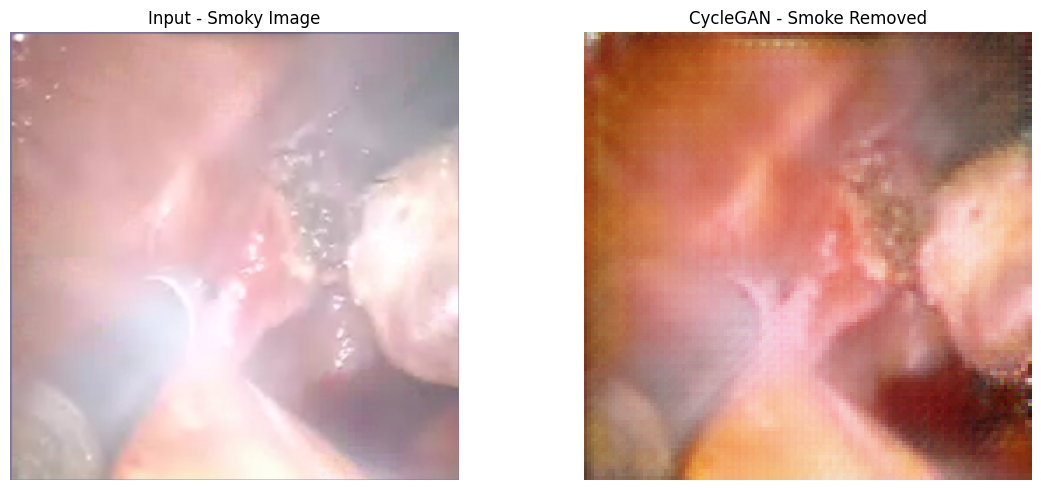

In [72]:
# ============================================================
# CYCLEGAN - TEST A SINGLE SMOKY IMAGE
# ============================================================

import torch
import torchvision.transforms as transforms
from PIL import Image
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Get uploaded image
# ------------------------------------------------------------

uploaded_file = upload.value[0]

filename = uploaded_file["name"]
content = uploaded_file["content"]

input_path = "/kaggle/working/smoky_input.png"

with open(input_path, "wb") as f:
    f.write(content)

print("Uploaded:", filename)


# ------------------------------------------------------------
# 2. Load trained CycleGAN generator
# ------------------------------------------------------------

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

checkpoint_path = (
    "CycleGAN_experiment/checkpoints/cyclegan_epoch_020.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device
)

G_AB = CycleGANGenerator(
    input_nc=3,
    output_nc=3,
    ngf=64,
    n_blocks=6
).to(device)

# Smoke -> Clear
G_AB.load_state_dict(checkpoint["G_AB"])

G_AB.eval()

print("CycleGAN generator loaded successfully.")


# ------------------------------------------------------------
# 3. Preprocess image
# ------------------------------------------------------------

transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(
        (0.5, 0.5, 0.5),
        (0.5, 0.5, 0.5)
    )
])

image = Image.open(input_path).convert("RGB")

input_tensor = transform(image).unsqueeze(0).to(device)


# ------------------------------------------------------------
# 4. Generate smoke-free image
# ------------------------------------------------------------

with torch.no_grad():
    output_tensor = G_AB(input_tensor)


# ------------------------------------------------------------
# 5. Convert output to image
# ------------------------------------------------------------

output_tensor = output_tensor.squeeze(0).cpu()

# [-1,1] -> [0,1]
output_tensor = (
    output_tensor * 0.5 + 0.5
).clamp(0, 1)

output_image = transforms.ToPILImage()(output_tensor)


# ------------------------------------------------------------
# 6. Save result
# ------------------------------------------------------------

output_path = (
    "CycleGAN_experiment/generated_clear/"
    "single_test_result.png"
)

output_image.save(output_path)

print("Result saved to:", output_path)


# ------------------------------------------------------------
# 7. Display Before vs After
# ------------------------------------------------------------

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Input - Smoky Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(output_image)
plt.title("CycleGAN - Smoke Removed")
plt.axis("off")

plt.tight_layout()
plt.show()

# FastCUT

In [31]:

# ================================================================
# FASTCUT-STYLE SURGICAL SMOKE REMOVAL: TRAIN + TEST + EVALUATE
# Dataset: /kaggle/input/private-dataset/SmokeRemovalDataset
# Outputs: /kaggle/working/FastCUT_experiment
# ================================================================

import os, sys, copy, random, subprocess, warnings, time
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.utils import save_image
from torchvision.models import inception_v3, Inception_V3_Weights
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA = Path("/kaggle/input/private-dataset/SmokeRemovalDataset")
ROOT = Path("/kaggle/working/FastCUT_experiment")
CKPT = ROOT / "checkpoints"
OUT = ROOT / "generated_clear"
CKPT.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)

SIZE = 128
BATCH = 1
EPOCHS = 20
LR = 2e-4
LAMBDA_NCE = 1.0
NCE_TEMPERATURE = 0.07
NUM_PATCHES = 128
AMP = device.type == "cuda"

print("Device:", device)
print("Dataset:", DATA)
print("Output:", ROOT)

# ----------------------- DATASET -----------------------

class SmokeDataset(Dataset):
    def __init__(self, folder):
        self.files = sorted(
            p for p in Path(folder).iterdir()
            if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp", ".webp"]
        )
        self.transform = transforms.Compose([
            transforms.Resize((SIZE, SIZE)),
            transforms.ToTensor(),
            transforms.Normalize((0.5,)*3, (0.5,)*3)
        ])
        if not self.files:
            raise RuntimeError(f"No images found in {folder}")

    def __len__(self):
        return len(self.files)

    def __getitem__(self, i):
        with Image.open(self.files[i]) as im:
            return self.transform(im.convert("RGB")), self.files[i].name

trainA = SmokeDataset(DATA / "trainA")
trainB = SmokeDataset(DATA / "trainB")
testA = SmokeDataset(DATA / "testA")
testB = SmokeDataset(DATA / "testB")

loaderA = DataLoader(trainA, batch_size=BATCH, shuffle=True,
                     num_workers=2, pin_memory=AMP, drop_last=True)
loaderB = DataLoader(trainB, batch_size=BATCH, shuffle=True,
                     num_workers=2, pin_memory=AMP, drop_last=True)
test_loader = DataLoader(testA, batch_size=1, shuffle=False, num_workers=2)

print(f"Train smoky={len(trainA)}, clear={len(trainB)}, "
      f"test smoky={len(testA)}, test clear={len(testB)}")

# ----------------------- NETWORKS -----------------------

class ResBlock(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.block = nn.Sequential(
            nn.ReflectionPad2d(1),
            nn.Conv2d(c, c, 3),
            nn.InstanceNorm2d(c),
            nn.ReLU(True),
            nn.ReflectionPad2d(1),
            nn.Conv2d(c, c, 3),
            nn.InstanceNorm2d(c)
        )

    def forward(self, x):
        return x + self.block(x)

class FastCUTGenerator(nn.Module):
    def __init__(self, ngf=64, n_blocks=6):
        super().__init__()
        self.stem = nn.Sequential(
            nn.ReflectionPad2d(3),
            nn.Conv2d(3, ngf, 7),
            nn.InstanceNorm2d(ngf),
            nn.ReLU(True)
        )
        self.down1 = nn.Sequential(
            nn.Conv2d(ngf, ngf*2, 3, 2, 1),
            nn.InstanceNorm2d(ngf*2), nn.ReLU(True)
        )
        self.down2 = nn.Sequential(
            nn.Conv2d(ngf*2, ngf*4, 3, 2, 1),
            nn.InstanceNorm2d(ngf*4), nn.ReLU(True)
        )
        self.res = nn.Sequential(*[ResBlock(ngf*4) for _ in range(n_blocks)])
        self.up1 = nn.Sequential(
            nn.ConvTranspose2d(ngf*4, ngf*2, 3, 2, 1, output_padding=1),
            nn.InstanceNorm2d(ngf*2), nn.ReLU(True)
        )
        self.up2 = nn.Sequential(
            nn.ConvTranspose2d(ngf*2, ngf, 3, 2, 1, output_padding=1),
            nn.InstanceNorm2d(ngf), nn.ReLU(True)
        )
        self.head = nn.Sequential(
            nn.ReflectionPad2d(3), nn.Conv2d(ngf, 3, 7), nn.Tanh()
        )

        # Feature projection heads used for patch contrastive learning
        self.projections = nn.ModuleList([
            nn.Sequential(nn.Conv2d(ngf, 128, 1), nn.ReLU(True)),
            nn.Sequential(nn.Conv2d(ngf*2, 128, 1), nn.ReLU(True)),
            nn.Sequential(nn.Conv2d(ngf*4, 128, 1), nn.ReLU(True)),
            nn.Sequential(nn.Conv2d(ngf*4, 128, 1), nn.ReLU(True))
        ])

    def encode(self, x):
        f1 = self.stem(x)
        f2 = self.down1(f1)
        f3 = self.down2(f2)
        f4 = self.res(f3)
        return [f1, f2, f3, f4]

    def decode(self, features):
        x = self.up1(features[3])
        x = self.up2(x)
        return self.head(x)

    def forward(self, x, return_features=False):
        features = self.encode(x)
        y = self.decode(features)
        if return_features:
            return y, features
        return y

class PatchDiscriminator(nn.Module):
    def __init__(self, ndf=64):
        super().__init__()
        layers = [
            nn.Conv2d(3, ndf, 4, 2, 1), nn.LeakyReLU(0.2, True)
        ]
        c = ndf
        for mult in [2, 4, 8]:
            layers += [
                nn.Conv2d(c, ndf*mult, 4, 2 if mult < 8 else 1, 1,
                          bias=False),
                nn.InstanceNorm2d(ndf*mult),
                nn.LeakyReLU(0.2, True)
            ]
            c = ndf*mult
        layers += [nn.Conv2d(c, 1, 4, 1, 1)]
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)

G = FastCUTGenerator().to(device)
D = PatchDiscriminator().to(device)
print("Generator parameters:", sum(p.numel() for p in G.parameters() if p.requires_grad))
print("Discriminator parameters:", sum(p.numel() for p in D.parameters() if p.requires_grad))

optG = torch.optim.Adam(G.parameters(), lr=LR, betas=(0.5, 0.999))
optD = torch.optim.Adam(D.parameters(), lr=LR, betas=(0.5, 0.999))
scalerG = torch.amp.GradScaler("cuda", enabled=AMP)
scalerD = torch.amp.GradScaler("cuda", enabled=AMP)
gan_loss = nn.MSELoss()

def patch_nce_loss(src_features, tgt_features, net, num_patches=NUM_PATCHES):
    losses = []
    for sf, tf, proj in zip(src_features, tgt_features, net.projections):
        # Match spatial positions in input and generated-image features
        a = proj(sf).flatten(2).transpose(1, 2)
        b = proj(tf).flatten(2).transpose(1, 2)
        n = min(num_patches, a.shape[1], b.shape[1])
        if n < 2:
            continue
        ids = torch.randperm(a.shape[1], device=a.device)[:n]
        a = F.normalize(a[:, ids, :].reshape(-1, a.shape[-1]), dim=1)
        b = F.normalize(b[:, ids, :].reshape(-1, b.shape[-1]), dim=1)
        logits = (a @ b.T) / NCE_TEMPERATURE
        labels = torch.arange(logits.shape[0], device=logits.device)
        losses.append(F.cross_entropy(logits, labels))
    return torch.stack(losses).mean() if losses else torch.tensor(0., device=device)

# ----------------------- TRAIN -----------------------

start = time.time()
history = []

for epoch in range(1, EPOCHS + 1):
    G.train()
    D.train()
    totals = {"G": 0., "GAN": 0., "NCE": 0., "D": 0.}
    steps = 0
    iterB = iter(loaderB)

    pbar = tqdm(loaderA, desc=f"FastCUT Epoch {epoch}/{EPOCHS}")
    for smoky, _ in pbar:
        try:
            clear, _ = next(iterB)
        except StopIteration:
            iterB = iter(loaderB)
            clear, _ = next(iterB)

        smoky = smoky.to(device, non_blocking=True)
        clear = clear.to(device, non_blocking=True)

        # Generator: adversarial + patch contrastive loss
        optG.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, enabled=AMP):
            fake_clear, fake_features = G(smoky, return_features=True)
            _, source_features = G(smoky, return_features=True)
            _, target_features = G(fake_clear, return_features=True)
            loss_nce = patch_nce_loss(source_features, target_features, G)
            loss_gan = gan_loss(D(fake_clear), torch.ones_like(D(fake_clear)))
            loss_G = loss_gan + LAMBDA_NCE * loss_nce

        scalerG.scale(loss_G).backward()
        scalerG.step(optG)
        scalerG.update()

        # Discriminator
        optD.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, enabled=AMP):
            pred_real = D(clear)
            pred_fake = D(fake_clear.detach())
            loss_D = 0.5 * (
                gan_loss(pred_real, torch.ones_like(pred_real)) +
                gan_loss(pred_fake, torch.zeros_like(pred_fake))
            )
        scalerD.scale(loss_D).backward()
        scalerD.step(optD)
        scalerD.update()

        totals["G"] += loss_G.item()
        totals["GAN"] += loss_gan.item()
        totals["NCE"] += loss_nce.item()
        totals["D"] += loss_D.item()
        steps += 1
        pbar.set_postfix(G=f"{loss_G.item():.3f}",
                         NCE=f"{loss_nce.item():.3f}",
                         D=f"{loss_D.item():.3f}")

    row = {"epoch": epoch, **{k: v/max(steps,1) for k,v in totals.items()}}
    history.append(row)
    pd.DataFrame(history).to_csv(ROOT / "training_history.csv", index=False)

    torch.save({
        "epoch": epoch,
        "G": G.state_dict(),
        "D": D.state_dict(),
        "optG": optG.state_dict(),
        "optD": optD.state_dict(),
        "history": history
    }, CKPT / "fastcut_latest.pth")

    print("Epoch summary:", row)

print(f"Training finished in {(time.time()-start)/3600:.2f} hours")

# ----------------------- GENERATE TEST OUTPUTS -----------------------

checkpoint = torch.load(CKPT / "fastcut_latest.pth", map_location=device)
G.load_state_dict(checkpoint["G"])
G.eval()

for p in OUT.iterdir():
    if p.is_file():
        p.unlink()

with torch.no_grad():
    for smoky, names in tqdm(test_loader, desc="Generating test images"):
        smoky = smoky.to(device)
        with torch.autocast(device_type=device.type, enabled=AMP):
            pred = G(smoky)
        pred = (pred.float().cpu() * 0.5 + 0.5).clamp(0, 1)
        name = Path(names[0]).stem + ".png"
        save_image(pred, OUT / name)

print("Generated images:", len(list(OUT.glob("*.png"))))
print("Saved to:", OUT)

# ----------------------- METRICS: FADE / PIQE / FID / KID -----------------------

# Install pyiqa if unavailable
try:
    import pyiqa
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pyiqa"])
    import pyiqa

metrics = {}
# FADE
try:
    from pyfade import fade_folder
    fade_result = fade_folder(str(OUT))
    metrics["FADE"] = float(fade_result.mean_score)
    print("FADE:", metrics["FADE"])
except Exception as e:
    print("FADE failed:", repr(e))

# PIQE
try:
    piqe_metric = pyiqa.create_metric("piqe", device=device)
    piqe_vals = []
    for f in tqdm(sorted(OUT.glob("*.png")), desc="PIQE"):
        im = pyiqa.imread(str(f), color_space="RGB").to(device)
        with torch.no_grad():
            piqe_vals.append(float(piqe_metric(im).mean().item()))
    metrics["PIQE"] = float(np.mean(piqe_vals))
    print("PIQE:", metrics["PIQE"])
except Exception as e:
    print("PIQE failed:", repr(e))

# FID: generated clear images vs real clear test set
try:
    fid_metric = pyiqa.create_metric("fid", device=device)
    metrics["FID"] = float(fid_metric(str(OUT), str(DATA / "testB")).item())
    print("FID:", metrics["FID"])
except Exception as e:
    print("FID failed:", repr(e))

# KID: Inception features + unbiased polynomial MMD estimate
try:
    inception = inception_v3(
        weights=Inception_V3_Weights.DEFAULT,
        aux_logits=True
    )
    inception.fc = nn.Identity()
    inception.eval().to(device)

    feature_transform = transforms.Compose([
        transforms.Resize((299, 299)),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )
    ])

    def extract_features(folder):
        files = sorted([
            p for p in Path(folder).iterdir()
            if p.suffix.lower() in [".png", ".jpg", ".jpeg", ".bmp", ".webp"]
        ])
        feats = []
        for p in tqdm(files, desc=f"KID features: {Path(folder).name}"):
            with Image.open(p) as im:
                x = feature_transform(im.convert("RGB")).unsqueeze(0).to(device)
            with torch.no_grad():
                feat = inception(x)
            feats.append(feat.flatten().cpu().numpy())
        return np.asarray(feats, dtype=np.float64)

    X = extract_features(OUT)
    Y = extract_features(DATA / "testB")
    rng = np.random.default_rng(SEED)
    subsets = 10
    subset_size = min(100, len(X), len(Y))
    kid_scores = []

    def poly_kernel(a, b):
        d = a.shape[1]
        return (a @ b.T / d + 1.0) ** 3

    for _ in range(subsets):
        ix = rng.choice(len(X), subset_size, replace=False)
        iy = rng.choice(len(Y), subset_size, replace=False)
        a, b = X[ix], Y[iy]
        Kxx, Kyy, Kxy = poly_kernel(a,a), poly_kernel(b,b), poly_kernel(a,b)
        m = subset_size
        score = (
            (Kxx.sum() - np.trace(Kxx)) / (m*(m-1)) +
            (Kyy.sum() - np.trace(Kyy)) / (m*(m-1)) -
            2*Kxy.mean()
        )
        kid_scores.append(float(score))

    metrics["KID_mean"] = float(np.mean(kid_scores))
    metrics["KID_std"] = float(np.std(kid_scores, ddof=1))
    print(f"KID: {metrics['KID_mean']:.8f} ± {metrics['KID_std']:.8f}")
except Exception as e:
    print("KID failed:", repr(e))

# ----------------------- SAVE RESULTS -----------------------

results = {
    "Model": "FastCUT-style",
    "Generated_images": len(list(OUT.glob("*.png"))),
    **metrics
}
pd.DataFrame([results]).to_csv(ROOT / "fastcut_metrics.csv", index=False)
print("\n" + "="*60)
print("FASTCUT-STYLE RESULTS")
print("="*60)
for k, v in results.items():
    print(f"{k}: {v}")
print("Metrics saved:", ROOT / "fastcut_metrics.csv")
print("Checkpoint:", CKPT / "fastcut_latest.pth")
print("Generated images:", OUT)


Device: cuda
Dataset: /kaggle/input/private-dataset/SmokeRemovalDataset
Output: /kaggle/working/FastCUT_experiment
Train smoky=1800, clear=1800, test smoky=600, test clear=600
Generator parameters: 7928323
Discriminator parameters: 2763841


FastCUT Epoch 1/20:   0%|          | 0/1800 [00:00<?, ?it/s]

Epoch summary: {'epoch': 1, 'G': 0.6515664158513149, 'GAN': 0.33513660997566247, 'NCE': 0.31642980580321617, 'D': 0.26374718744721676}


FastCUT Epoch 2/20:   0%|          | 0/1800 [00:00<?, ?it/s]

Epoch summary: {'epoch': 2, 'G': 0.42377638198849227, 'GAN': 0.3168466523465597, 'NCE': 0.10692972938840588, 'D': 0.2516510795077516}


...

FID: 281.4203172484739
Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /root/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth


100%|██████████| 104M/104M [00:00<00:00, 196MB/s] 


KID features: generated_clear:   0%|          | 0/600 [00:00<?, ?it/s]

KID features: testB:   0%|          | 0/600 [00:00<?, ?it/s]

KID: 0.12130396 ± 0.00596724

FASTCUT-STYLE RESULTS
Model: FastCUT-style
Generated_images: 600
FID: 281.4203172484739
KID_mean: 0.12130395522706872
KID_std: 0.005967238974857859
Metrics saved: /kaggle/working/FastCUT_experiment/fastcut_metrics.csv
Checkpoint: /kaggle/working/FastCUT_experiment/checkpoints/fastcut_latest.pth
Generated images: /kaggle/working/FastCUT_experiment/generated_clear


In [33]:

import sys, subprocess

# Install the correct distribution name
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q", "fade-python"
])

# Evaluate FADE on the existing FastCUT outputs
from pyfade import fade_folder

from pathlib import Path
import pandas as pd

output_dir = Path(
    "/kaggle/working/FastCUT_experiment/generated_clear"
)

result = fade_folder(str(output_dir), workers=2, progress=True)
fade_score = float(result.mean_score)

print(f"FastCUT FADE: {fade_score:.6f}")
print(f"Images evaluated: {len(result.scores)}")

# Save score
result_path = Path(
    "/kaggle/working/FastCUT_experiment/fastcut_fade_result.csv"
)
pd.DataFrame([{
    "Model": "FastCUT-style",
    "FADE": fade_score,
    "Images_Evaluated": len(result.scores)
}]).to_csv(result_path, index=False)

print("Saved:", result_path)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.9/3.9 MB 55.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 78.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 95.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 563.0/563.0 kB 26.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.7/59.7 MB 25.4 MB/s eta 0:00:00


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.39.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
ydata-profiling 4.18.4 requires numba<0.63,>=0.60, but you have numba 0.68.0 which is incompatible.
ydata-profiling 4.18.4 requires numpy<2.4,>=1.22, but you have numpy 2.5.4 which is incompatible.
google-colab 1.0.0 requires jupyter-server==2.14.0, but you have jupyter-server 2.12.5 which is incompatible.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 2.3.3 which is incompatible.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.
cuml-cu12 26.2.0 requires numba<0.62.0,>=0.60.0, but you have numba 0.68.0 which is incompatible.
cudf-cu12 26.2.1 requires numba<0.62.0,>=0.60.

pyfade:   0%|          | 0/600 [00:00<?, ?it/s]

FastCUT FADE: 0.242386
Images evaluated: 600
Saved: /kaggle/working/FastCUT_experiment/fastcut_fade_result.csv


In [34]:

import torch
import numpy as np
import pandas as pd
import pyiqa
from pathlib import Path
from PIL import Image
from torchvision.transforms.functional import to_tensor
from tqdm.auto import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
out_dir = Path("/kaggle/working/FastCUT_experiment/generated_clear")

metric = pyiqa.create_metric("piqe", device=device)
scores = []

files = sorted(out_dir.glob("*.png"))

for path in tqdm(files, desc="Calculating PIQE"):
    with Image.open(path) as im:
        image = to_tensor(im.convert("RGB")).unsqueeze(0).to(device)

    with torch.no_grad():
        score = metric(image)

    scores.append(score.mean().item())

piqe_score = float(np.mean(scores))

print(f"FastCUT PIQE: {piqe_score:.6f}")
print(f"Images evaluated: {len(scores)}/{len(files)}")

result_path = Path(
    "/kaggle/working/FastCUT_experiment/fastcut_piqe_result.csv"
)

pd.DataFrame([{
    "Model": "FastCUT-style",
    "PIQE": piqe_score,
    "Images_Evaluated": len(scores)
}]).to_csv(result_path, index=False)

print("Saved:", result_path)


Calculating PIQE:   0%|          | 0/600 [00:00<?, ?it/s]

FastCUT PIQE: 14.578081
Images evaluated: 600/600
Saved: /kaggle/working/FastCUT_experiment/fastcut_piqe_result.csv


# Cycle-Dehaze

In [ ]:

import os, sys, time, random, subprocess, warnings
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.utils import save_image

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA = Path("/kaggle/input/private-dataset/SmokeRemovalDataset")
ROOT = Path("/kaggle/working/CycleDehaze_experiment")
CKPT = ROOT / "checkpoints"
OUT = ROOT / "generated_clear"
for p in [CKPT, OUT]:
    p.mkdir(parents=True, exist_ok=True)

SIZE, EPOCHS, LR = 128, 20, 2e-4
AMP = device.type == "cuda"
print("Device:", device)

# -------------------------- DATASET --------------------------

class SmokeDataset(Dataset):
    def __init__(self, folder):
        self.files = sorted([
            p for p in Path(folder).iterdir()
            if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp", ".webp"]
        ])
        self.tf = transforms.Compose([
            transforms.Resize((SIZE, SIZE)),
            transforms.ToTensor(),
            transforms.Normalize((0.5,)*3, (0.5,)*3)
        ])
        if not self.files:
            raise RuntimeError(f"No images found: {folder}")

    def __len__(self):
        return len(self.files)

    def __getitem__(self, i):
        with Image.open(self.files[i]) as im:
            return self.tf(im.convert("RGB")), self.files[i].name

trainA = SmokeDataset(DATA / "trainA")
trainB = SmokeDataset(DATA / "trainB")
testA = SmokeDataset(DATA / "testA")

loaderA = DataLoader(trainA, batch_size=1, shuffle=True, num_workers=2)
loaderB = DataLoader(trainB, batch_size=1, shuffle=True, num_workers=2)
test_loader = DataLoader(testA, batch_size=1, shuffle=False, num_workers=2)
print("Train A:", len(trainA), "Train B:", len(trainB), "Test:", len(testA))

# -------------------------- NETWORKS --------------------------

class ResBlock(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.net = nn.Sequential(
            nn.ReflectionPad2d(1), nn.Conv2d(c, c, 3),
            nn.InstanceNorm2d(c), nn.ReLU(True),
            nn.ReflectionPad2d(1), nn.Conv2d(c, c, 3),
            nn.InstanceNorm2d(c)
        )

    def forward(self, x):
        return x + self.net(x)

class Generator(nn.Module):
    def __init__(self, ngf=64, blocks=6):
        super().__init__()
        self.net = nn.Sequential(
            nn.ReflectionPad2d(3), nn.Conv2d(3, ngf, 7),
            nn.InstanceNorm2d(ngf), nn.ReLU(True),
            nn.Conv2d(ngf, ngf*2, 3, 2, 1),
            nn.InstanceNorm2d(ngf*2), nn.ReLU(True),
            nn.Conv2d(ngf*2, ngf*4, 3, 2, 1),
            nn.InstanceNorm2d(ngf*4), nn.ReLU(True),
            *[ResBlock(ngf*4) for _ in range(blocks)],
            nn.ConvTranspose2d(ngf*4, ngf*2, 3, 2, 1, output_padding=1),
            nn.InstanceNorm2d(ngf*2), nn.ReLU(True),
            nn.ConvTranspose2d(ngf*2, ngf, 3, 2, 1, output_padding=1),
            nn.InstanceNorm2d(ngf), nn.ReLU(True),
            nn.ReflectionPad2d(3), nn.Conv2d(ngf, 3, 7), nn.Tanh()
        )

    def forward(self, x):
        return self.net(x)

class Discriminator(nn.Module):
    def __init__(self, ndf=64):
        super().__init__()
        layers = [
            nn.Conv2d(3, ndf, 4, 2, 1), nn.LeakyReLU(.2, True)
        ]
        c = ndf
        for mult, stride in [(2, 2), (4, 2), (8, 1)]:
            layers += [
                nn.Conv2d(c, ndf*mult, 4, stride, 1, bias=False),
                nn.InstanceNorm2d(ndf*mult), nn.LeakyReLU(.2, True)
            ]
            c = ndf*mult
        layers.append(nn.Conv2d(c, 1, 4, 1, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

G_AB, G_BA = Generator().to(device), Generator().to(device)
D_A, D_B = Discriminator().to(device), Discriminator().to(device)

optG = torch.optim.Adam(
    list(G_AB.parameters()) + list(G_BA.parameters()),
    lr=LR, betas=(.5, .999)
)
optDA = torch.optim.Adam(D_A.parameters(), lr=LR, betas=(.5, .999))
optDB = torch.optim.Adam(D_B.parameters(), lr=LR, betas=(.5, .999))
gan = nn.MSELoss()
l1 = nn.L1Loss()
scaler = torch.amp.GradScaler("cuda", enabled=AMP)

# Replay buffers
class ReplayBuffer:
    def __init__(self, capacity=50):
        self.capacity, self.data = capacity, []

    def push_and_pop(self, batch):
        out = []
        for img in batch.detach():
            img = img.unsqueeze(0)
            if len(self.data) < self.capacity:
                self.data.append(img)
                out.append(img)
            elif random.random() > .5:
                i = random.randrange(self.capacity)
                old = self.data[i].clone()
                self.data[i] = img
                out.append(old)
            else:
                out.append(img)
        return torch.cat(out)

bufferA, bufferB = ReplayBuffer(), ReplayBuffer()

# -------------------------- TRAINING --------------------------

history = []
start = time.time()

for epoch in range(1, EPOCHS + 1):
    G_AB.train(); G_BA.train(); D_A.train(); D_B.train()
    iterB = iter(loaderB)
    totals = np.zeros(4, dtype=float)
    steps = 0

    for realA, _ in tqdm(loaderA, desc=f"Epoch {epoch}/{EPOCHS}"):
        try:
            realB, _ = next(iterB)
        except StopIteration:
            iterB = iter(loaderB)
            realB, _ = next(iterB)

        realA, realB = realA.to(device), realB.to(device)

        # Generators
        optG.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, enabled=AMP):
            fakeB = G_AB(realA)
            fakeA = G_BA(realB)
            recA = G_BA(fakeB)
            recB = G_AB(fakeA)
            idA = G_BA(realA)
            idB = G_AB(realB)

            loss_gan_AB = gan(D_B(fakeB), torch.ones_like(D_B(fakeB)))
            loss_gan_BA = gan(D_A(fakeA), torch.ones_like(D_A(fakeA)))
            loss_cycle = l1(recA, realA) + l1(recB, realB)
            loss_id = l1(idA, realA) + l1(idB, realB)
            loss_G = loss_gan_AB + loss_gan_BA + 10*loss_cycle + 5*loss_id

        scaler.scale(loss_G).backward()
        scaler.step(optG)
        scaler.update()

        # Discriminator A
        optDA.zero_grad(set_to_none=True)
        fakeA_buf = bufferA.push_and_pop(fakeA)
        with torch.autocast(device_type=device.type, enabled=AMP):
            pr = D_A(realA)
            pf = D_A(fakeA_buf.detach())
            loss_DA = .5*(gan(pr, torch.ones_like(pr)) + gan(pf, torch.zeros_like(pf)))
        scaler.scale(loss_DA).backward()
        scaler.step(optDA)
        scaler.update()

        # Discriminator B
        optDB.zero_grad(set_to_none=True)
        fakeB_buf = bufferB.push_and_pop(fakeB)
        with torch.autocast(device_type=device.type, enabled=AMP):
            pr = D_B(realB)
            pf = D_B(fakeB_buf.detach())
            loss_DB = .5*(gan(pr, torch.ones_like(pr)) + gan(pf, torch.zeros_like(pf)))
        scaler.scale(loss_DB).backward()
        scaler.step(optDB)
        scaler.update()

        totals += [loss_G.item(), loss_gan_AB.item(), loss_cycle.item(), 
                   (loss_DA.item()+loss_DB.item())/2]
        steps += 1

    row = dict(zip(["G", "GAN_AB", "Cycle", "D_mean"], totals/max(steps,1)))
    row["epoch"] = epoch
    history.append(row)
    pd.DataFrame(history).to_csv(ROOT / "training_history.csv", index=False)

    torch.save({
        "epoch": epoch,
        "G_AB": G_AB.state_dict(),
        "G_BA": G_BA.state_dict(),
        "D_A": D_A.state_dict(),
        "D_B": D_B.state_dict(),
        "history": history
    }, CKPT / "cycledehaze_latest.pth")
    print("Epoch summary:", row)

print(f"Training time: {(time.time()-start)/3600:.2f} hours")

# -------------------------- GENERATE TEST IMAGES --------------------------

G_AB.eval()
with torch.no_grad():
    for smoky, names in tqdm(test_loader, desc="Generating test outputs"):
        smoky = smoky.to(device)
        with torch.autocast(device_type=device.type, enabled=AMP):
            result = G_AB(smoky)
        result = (result.float().cpu()*0.5 + 0.5).clamp(0,1)
        save_image(result, OUT / (Path(names[0]).stem + ".png"))

print("Generated:", len(list(OUT.glob("*.png"))), "images")

# -------------------------- EVALUATE METRICS --------------------------

try:
    import pyiqa
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pyiqa"])
    import pyiqa

metrics = {}

# FADE (uses the installed fade-python distribution)
try:
    from pyfade import fade_folder
    fade_result = fade_folder(str(OUT), workers=2, progress=True)
    metrics["FADE"] = float(fade_result.mean_score)
    print("FADE:", metrics["FADE"])
except Exception as e:
    print("FADE failed:", repr(e))

# PIQE
try:
    piqe = pyiqa.create_metric("piqe", device=device)
    scores = []
    for p in tqdm(sorted(OUT.glob("*.png")), desc="PIQE"):
        with Image.open(p) as im:
            x = transforms.ToTensor()(im.convert("RGB")).unsqueeze(0).to(device)
        with torch.no_grad():
            scores.append(float(piqe(x).mean().item()))
    metrics["PIQE"] = float(np.mean(scores))
    print("PIQE:", metrics["PIQE"])
except Exception as e:
    print("PIQE failed:", repr(e))

# FID
try:
    fid = pyiqa.create_metric("fid", device=device)
    metrics["FID"] = float(fid(str(OUT), str(DATA/"testB")).item())
    print("FID:", metrics["FID"])
except Exception as e:
    print("FID failed:", repr(e))

# KID (Inception features + unbiased polynomial MMD)
try:
    from torchvision.models import inception_v3, Inception_V3_Weights
    inception = inception_v3(weights=Inception_V3_Weights.DEFAULT, aux_logits=True)
    inception.fc = nn.Identity()
    inception.eval().to(device)
    ft = transforms.Compose([
        transforms.Resize((299,299)),
        transforms.ToTensor(),
        transforms.Normalize([.485,.456,.406],[.229,.224,.225])
    ])

    def features(folder):
        files = sorted([
            p for p in Path(folder).iterdir()
            if p.suffix.lower() in [".png",".jpg",".jpeg",".bmp",".webp"]
        ])
        arr = []
        for p in tqdm(files, desc="KID features"):
            with Image.open(p) as im:
                x = ft(im.convert("RGB")).unsqueeze(0).to(device)
            with torch.no_grad():
                arr.append(inception(x).flatten().cpu().numpy())
        return np.asarray(arr, dtype=np.float64)

    X, Y = features(OUT), features(DATA/"testB")
    rng = np.random.default_rng(SEED)
    n = min(100, len(X), len(Y))
    vals = []

    def kernel(a,b):
        return (a @ b.T / a.shape[1] + 1)**3

    for _ in range(10):
        a, b = X[rng.choice(len(X),n,False)], Y[rng.choice(len(Y),n,False)]
        xx, yy, xy = kernel(a,a), kernel(b,b), kernel(a,b)
        vals.append(
            (xx.sum()-np.trace(xx))/(n*(n-1)) +
            (yy.sum()-np.trace(yy))/(n*(n-1)) -
            2*xy.mean()
        )

    metrics["KID_mean"] = float(np.mean(vals))
    metrics["KID_std"] = float(np.std(vals, ddof=1))
    print(f"KID: {metrics['KID_mean']:.8f} ± {metrics['KID_std']:.8f}")
except Exception as e:
    print("KID failed:", repr(e))

# -------------------------- SAVE FINAL RESULTS --------------------------

results = {
    "Model": "Cycle-Dehaze-style",
    "Generated_images": len(list(OUT.glob("*.png"))),
    **metrics
}
pd.DataFrame([results]).to_csv(ROOT / "cycledehaze_metrics.csv", index=False)

print("\n" + "="*60)
print("CYCLE-DEHAZE-STYLE FINAL RESULTS")
print("="*60)
for k,v in results.items():
    print(f"{k}: {v}")
print("Results:", ROOT / "cycledehaze_metrics.csv")
print("Checkpoint:", CKPT / "cycledehaze_latest.pth")
print("Generated images:", OUT)


Device: cuda
Train A: 1800 Train B: 1800 Test: 600


Epoch 1/20:   0%|          | 0/1800 [00:00<?, ?it/s]

Epoch summary: {'G': np.float64(7.457336843676037), 'GAN_AB': np.float64(0.37049286934702347), 'Cycle': np.float64(0.4543300047516823), 'D_mean': np.float64(0.2298373161494318), 'epoch': 1}


Epoch 2/20:   0%|          | 0/1800 [00:00<?, ?it/s]

Epoch summary: {'G': np.float64(6.491890880531735), 'GAN_AB': np.float64(0.3802628041146737), 'Cycle': np.float64(0.3888578269216749), 'D_mean': np.float64(0.2001236198332885), 'epoch': 2}


...

FID testB: 100%|██████████| 75/75 [00:06<00:00, 11.92it/s]


FID: 152.17989003876252


KID features:   0%|          | 0/600 [00:00<?, ?it/s]

KID features:   0%|          | 0/600 [00:00<?, ?it/s]

KID: 0.06882939 ± 0.00624803

CYCLE-DEHAZE-STYLE FINAL RESULTS
Model: Cycle-Dehaze-style
Generated_images: 600
FADE: 0.3358871598347384
PIQE: 16.570271821022033
FID: 152.17989003876252
KID_mean: 0.06882938981660502
KID_std: 0.006248027352064767
Results: /kaggle/working/CycleDehaze_experiment/cycledehaze_metrics.csv
Checkpoint: /kaggle/working/CycleDehaze_experiment/checkpoints/cycledehaze_latest.pth
Generated images: /kaggle/working/CycleDehaze_experiment/generated_clear


In [1]:

from pathlib import Path

roots = [
    Path("/kaggle/input"),
    Path("/kaggle/working")
]

keywords = ["desmoke", "smoke", "checkpoint", "best.pt", "best.pth"]

print("=" * 65)
print("SEARCHING FOR EXISTING MODEL WEIGHTS")
print("=" * 65)

found = []

for root in roots:
    for p in root.rglob("*"):
        if not p.is_file():
            continue

        name = p.name.lower()
        if (
            p.suffix.lower() in [".pth", ".pt", ".ckpt", ".onnx"]
            and any(k in name for k in keywords)
        ):
            found.append(p)
            print(p)

print("\n" + "=" * 65)
print("SEARCHING FOR DATASET AND MODEL DOCUMENTATION")
print("=" * 65)

for p in Path("/kaggle/input").rglob("*"):
    if p.is_file() and any(
        k in p.name.lower() for k in ["readme", "desmoke", "config"]
    ):
        print(p)

if not found:
    print("\nNo matching pretrained weights found.")
    print("Do not treat a newly implemented approximation as the official model.")


SEARCHING FOR EXISTING MODEL WEIGHTS

SEARCHING FOR DATASET AND MODEL DOCUMENTATION

No matching pretrained weights found.
Do not treat a newly implemented approximation as the official model.


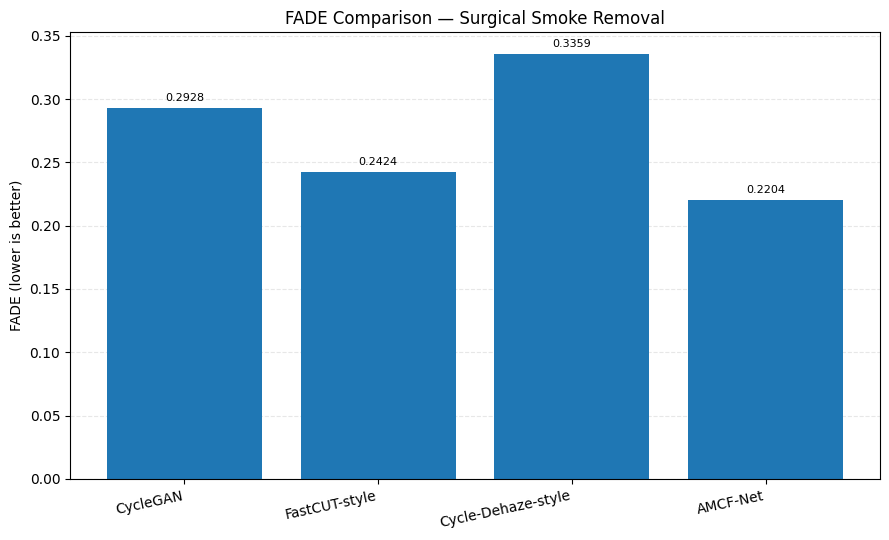

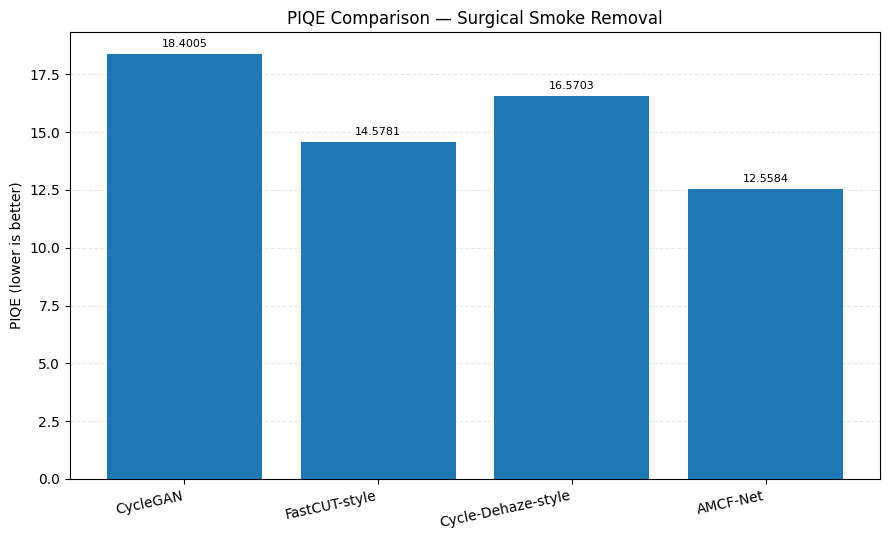

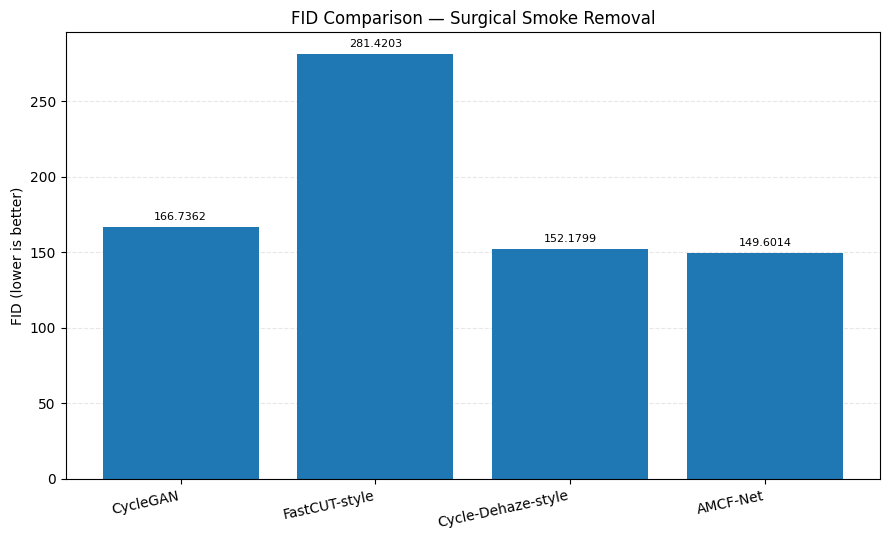

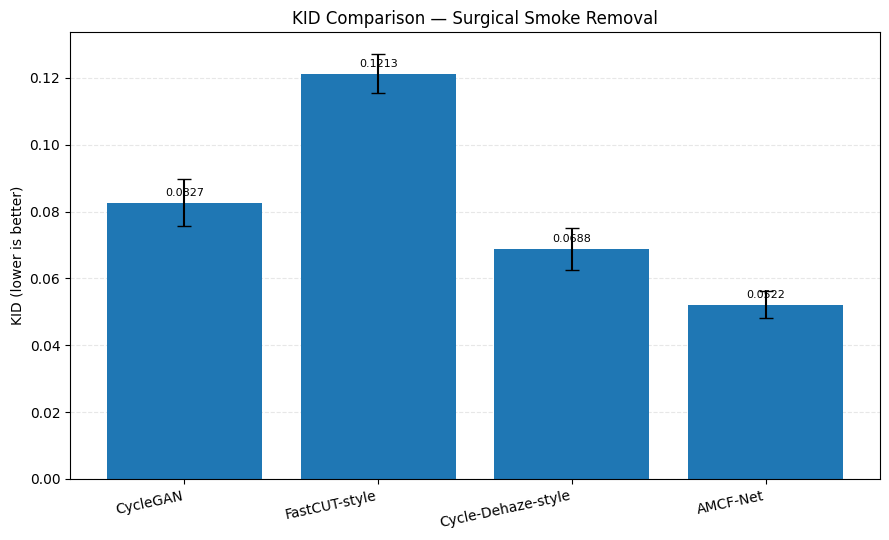


FINAL COMPARISON
             Model     FADE      PIQE        FID  KID_mean  KID_std
          CycleGAN 0.292845 18.400478 166.736222  0.082698 0.006943
     FastCUT-style 0.242386 14.578081 281.420317  0.121304 0.005967
Cycle-Dehaze-style 0.335887 16.570272 152.179890  0.068829 0.006248
          AMCF-Net 0.220436 12.558423 149.601400  0.052156 0.004020

Files saved to: /kaggle/working/Final_Results


In [5]:

import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

out_dir = Path("/kaggle/working/Final_Results")
out_dir.mkdir(parents=True, exist_ok=True)

models = [
    "CycleGAN",
    "FastCUT-style",
    "Cycle-Dehaze-style",
    "AMCF-Net"
]

results = {
    "FADE": [0.292845, 0.242386, 0.335887, 0.220436],
    "PIQE": [18.400478, 14.578081, 16.570272, 12.558423],
    "FID": [166.736222, 281.420317, 152.179890, 149.601400],
    "KID": [0.08269813, 0.12130396, 0.06882939, 0.05215621]
}

kid_std = [0.00694319, 0.00596724, 0.00624803, 0.00402027]

for metric, values in results.items():
    fig, ax = plt.subplots(figsize=(9, 5.5))

    bars = ax.bar(models, values)

    # Show KID standard deviations as error bars
    if metric == "KID":
        ax.errorbar(
            range(len(models)),
            values,
            yerr=kid_std,
            fmt="none",
            capsize=5,
            color="black"
        )

    ax.set_title(f"{metric} Comparison — Surgical Smoke Removal")
    ax.set_ylabel(f"{metric} (lower is better)")
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    ax.set_axisbelow(True)

    for bar, value in zip(bars, values):
        ax.annotate(
            f"{value:.4f}",
            (bar.get_x() + bar.get_width()/2, bar.get_height()),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            fontsize=8
        )

    plt.xticks(rotation=12, ha="right")
    plt.tight_layout()
    fig.savefig(
        out_dir / f"{metric.lower()}_comparison.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

df = pd.DataFrame({
    "Model": models,
    "FADE": results["FADE"],
    "PIQE": results["PIQE"],
    "FID": results["FID"],
    "KID_mean": results["KID"],
    "KID_std": kid_std
})

df.to_csv(out_dir / "experimental_results_with_amcf.csv", index=False)

print("\nFINAL COMPARISON")
print(df.to_string(index=False))
print("\nFiles saved to:", out_dir)


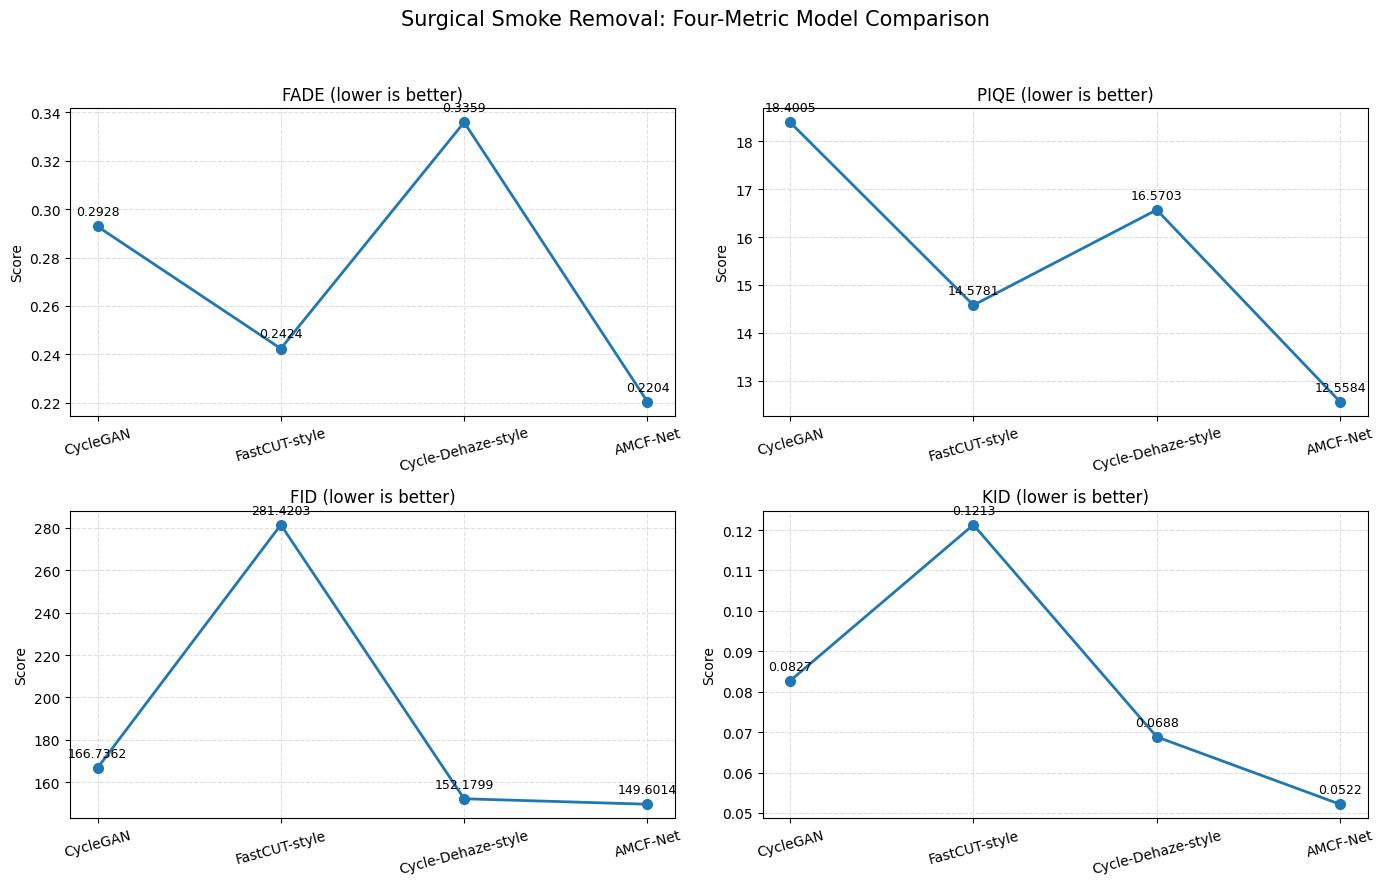

Graph saved to: /kaggle/working/Final_Results/all_four_metrics_line_graph.png


In [8]:

import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

# Save location
out_dir = Path("/kaggle/working/Final_Results")
out_dir.mkdir(parents=True, exist_ok=True)

models = [
    "CycleGAN",
    "FastCUT-style",
    "Cycle-Dehaze-style",
    "AMCF-Net"
]

# Measured results for the three baseline experiments
# AMCF-Net uses your previously recorded evaluation
scores = {
    "FADE": [0.292845, 0.242386, 0.335887, 0.220436],
    "PIQE": [18.400478, 14.578081, 16.570272, 12.558423],
    "FID": [166.736222, 281.420317, 152.179890, 149.601400],
    "KID": [0.08269813, 0.12130396, 0.06882939, 0.05215621]
}


fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

for ax, (metric, values) in zip(axes, scores.items()):
    ax.plot(
        models, values,
        marker="o",
        linewidth=2,
        markersize=7
    )

    for i, value in enumerate(values):
        ax.annotate(
            f"{value:.4f}",
            (i, value),
            textcoords="offset points",
            xytext=(0, 8),
            ha="center",
            fontsize=9
        )

    ax.set_title(f"{metric} (lower is better)")
    ax.set_ylabel("Score")
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.tick_params(axis="x", rotation=15)

fig.suptitle(
    "Surgical Smoke Removal: Four-Metric Model Comparison",
    fontsize=15
)
fig.tight_layout(rect=[0, 0, 1, 0.95])

save_path = out_dir / "all_four_metrics_line_graph.png"
fig.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print("Graph saved to:", save_path)
